## **1. Business Understanding**

Recommender systems are a core component of modern digital platforms. Streaming
services, e-commerce sites, and content platforms all rely on data-driven
recommendations to increase user engagement, retention, and revenue. Netflix
estimates that over 80% of content watched is driven by recommendations; Spotify
attributes a significant share of listening time to personalised playlists.

In this project, which follows the **CRISP-DM** methodology (Cross-Industry Standard Process
for Data Mining), we will work with the **MovieLens ml-latest-small** dataset, a
real-world dataset of movie ratings collected by GroupLens Research. Our goal is
to build and evaluate recommendation models that suggest relevant movies to users
based on their past behaviour.

### 1.1 Business Problem

A movie streaming platform wants to **increase user engagement** by surfacing
films that each user is likely to enjoy. Without personalisation, users face
choice overload across thousands of titles, leading to decision fatigue and
lower watch rates.

The business objective is to **automatically rank and recommend movies** to
each user in a way that maximises the chance they watch and enjoy them.

A natural **baseline** for any recommender system is a non-personalised
popularity model — simply recommending the most-rated movies to all users.
This is cheap to compute and often surprisingly strong. Any personalised model
must demonstrably outperform this baseline to justify its added complexity.

**Success criteria (business level):**
- Users receive recommendations they find relevant (high click/watch rate)
- Users discover content they would not have found manually
- Recommendations are diverse enough to avoid filter bubbles

**Success criteria (ML level):**
- Personalised models achieve higher Precision@3 and Recall@3 than the popularity baseline
- The best model is selected based on performance on a held-out validation set
- Results are consistent across both binary and non-binary evaluation scenarios

### 1.2 Translation into Machine Learning Problems

The business problem can be framed in two complementary ways:

**Binary (implicit feedback) setting:**  
Did the user interact with the item? This treats any rating as a positive
signal and formulates the problem as ranking items by predicted interaction
probability. Suitable for BPR and NCF.

**Non-binary (explicit feedback) setting:**  
Can we predict the exact rating a user would give a movie?
This is a regression/ranking problem, suitable for CF and MF approaches.

Both framings will be evaluated using **Precision@3** and **Recall@3**.

**Operational constraints to keep in mind:**
- Cold-start: new users or new movies have no rating history
- Sparsity: most user–item pairs are unobserved, not necessarily negative
- Scalability: in production, recommendations must be generated in real time
- Temporal drift: user tastes evolve — older ratings may be less relevant

<h3>1.3 Summary</h3>

<table style="width:100%; border-collapse: collapse; font-size: 18px;">
  <thead>
    <tr style="background-color:#f2f2f2;">
      <th style="text-align:left; padding:30px 20px; width:20%;">Aspect</th>
      <th style="text-align:left; padding:30px 20px; width:80%;">Detail</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="padding:30px 20px;"><b>Business goal</b></td><td style="padding:30px 20px;">Increase user engagement via personalised movie recommendations</td></tr>
    <tr><td style="padding:30px 20px;"><b>Dataset</b></td><td style="padding:30px 20px;">MovieLens ml-latest-small — ~100K ratings, 610 users, ~9K movies</td></tr>
    <tr><td style="padding:30px 20px;"><b>Approaches</b></td><td style="padding:30px 20px;">AR, CF, MFPQ, BPR, NCF</td></tr>
    <tr><td style="padding:30px 20px;"><b>Metrics</b></td><td style="padding:30px 20px;">Precision@3 and Recall@3 — binary and non-binary scenarios</td></tr>
    <tr><td style="padding:30px 20px;"><b>Key constraints</b></td><td style="padding:30px 20px;">Data sparsity (~98% unobserved), cold-start, temporal drift, scalability</td></tr>
    <tr><td style="padding:30px 20px;"><b>Evaluation strategy</b></td><td style="padding:30px 20px;">Probe on 20% subsample → validate best models on full dataset</td></tr>
  </tbody>
</table>

### 1.4 Conclusion

This section established the business framing of the problem. The objective is to
build personalised movie recommendation models that outperform a simple popularity
baseline, evaluated using **Precision** and **Recall** in both explicit and implicit feedback settings.

The constraints identified here like **data sparsity**, **cold-start**, **temporal
drift**, and **scalability** will inform key modelling decisions in the sections
that follow. In particular, the cold-start limitation means that purely
collaborative approaches will have inherent blind spots for new users or items,
which is an important consideration when proposing a final production-ready solution.

The next section explores the data in depth to validate these assumptions and
better understand the characteristics of the rating distribution.

## **2. Data Understanding**

This section explores the MovieLens ml-latest-small dataset, focusing on the ratings table.
The goal is to understand the structure of the data, characterize the number of users and items,
and analyze the distribution of basket size (number of ratings per user) to determine whether
it follows a power law.

The dataset was collected by GroupLens Research and contains ratings applied to movies by users
of the MovieLens website. Each user has rated at least 20 movies, and ratings are made on a
5-star scale with half-star increments.

We will begin this work by loading the datasets using the pandas python library and then check the statistic distribution and matrix sparsity, as well as mean, quartile and standard deviation values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
ratings = pd.read_csv('sample_data/ratings.csv')
movies = pd.read_csv('sample_data/movies.csv')

# First look
print("Shape:", ratings.shape)
print("\nFirst rows:")
ratings.head()

Shape: (100836, 4)

First rows:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [2]:
print("Data types:\n", ratings.dtypes)
print("\nMissing values:\n", ratings.isnull().sum())
print("\nBasic statistics:")
ratings.describe()

Data types:
 userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Missing values:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Basic statistics:


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [3]:
n_users = ratings['userId'].nunique()
n_items = ratings['movieId'].nunique()
n_ratings = len(ratings)
sparsity = 1 - (n_ratings / (n_users * n_items))

print(f"Number of users:   {n_users}")
print(f"Number of movies:  {n_items}")
print(f"Number of ratings: {n_ratings}")
print(f"Matrix sparsity:   {sparsity:.4%}")

Number of users:   610
Number of movies:  9724
Number of ratings: 100836
Matrix sparsity:   98.3000%


### Observations regarding the initial analysis

**Goal:** understand the basic structure and quality of the ratings data before any transformation.

**Structure:** the ratings table contains 100,836 ratings across 4 columns: userId, movieId, rating, and timestamp. There are no missing values, so no imputation is needed.

**Rating scale:** ratings range from 0.5 to 5.0 in 0.5 increments. The mean rating is 3.5, suggesting a slight positive bias — users tend to rate movies they chose to watch, not random selections.

**Sparsity:** with 610 users and 9,742 movies, the user-item matrix has ~5.9 million possible entries but only 100,836 observed ratings, yielding a sparsity of ~98.3%. This is the central challenge for all collaborative filtering methods — most user-item pairs are unobserved, and absence of a rating does not mean the user dislikes the film.

## Basket Size Distribution

The "basket size" refers to the number of ratings each user has given.
We analyze its distribution to understand user engagement and check whether it follows a power law.

In [4]:
# Ratings per user
ratings_per_user = ratings.groupby('userId')['movieId'].count()

# Ratings per movie
ratings_per_movie = ratings.groupby('movieId')['userId'].count()

print("Ratings per User")
print(f"Mean:   {ratings_per_user.mean():.1f}")
print(f"Median: {ratings_per_user.median():.1f}")
print(f"Min:    {ratings_per_user.min()}")
print(f"Max:    {ratings_per_user.max()}")

print("\nRatings per Movie")
print(f"Mean:   {ratings_per_movie.mean():.1f}")
print(f"Median: {ratings_per_movie.median():.1f}")
print(f"Min:    {ratings_per_movie.min()}")
print(f"Max:    {ratings_per_movie.max()}")

Ratings per User
Mean:   165.3
Median: 70.5
Min:    20
Max:    2698

Ratings per Movie
Mean:   10.4
Median: 3.0
Min:    1
Max:    329


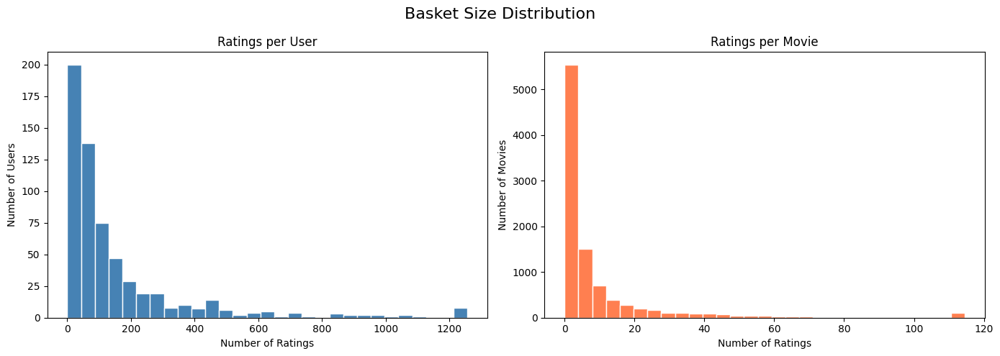

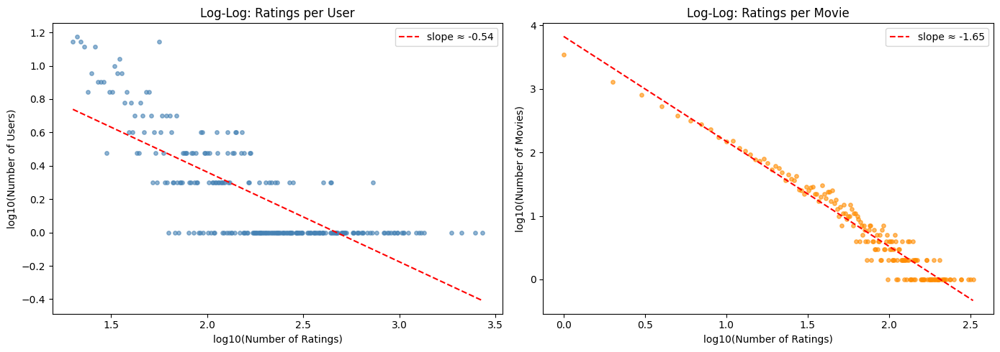

In [5]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Basket Size Distribution', fontsize=16)

# Ratings per User
max_user = ratings_per_user.quantile(0.99)
bins = np.linspace(0, max_user, 30)
axes[0].hist(ratings_per_user.clip(upper=max_user), bins=bins,
             color='steelblue', edgecolor='white')
axes[0].set_title('Ratings per User')
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Number of Users')

# Ratings per Movie
max_movie = ratings_per_movie.quantile(0.99)
bins = np.linspace(0, max_movie, 30)
axes[1].hist(ratings_per_movie.clip(upper=max_movie), bins=bins,
             color='coral', edgecolor='white')
axes[1].set_title('Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Number of Movies')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-log: Ratings per User
user_counts = ratings.groupby('userId').size()
user_freq = user_counts.value_counts().sort_index()
axes[0].scatter(np.log10(user_freq.index), np.log10(user_freq.values),
                alpha=0.6, color='steelblue', s=15)

# Fit line
coeffs = np.polyfit(np.log10(user_freq.index), np.log10(user_freq.values), 1)
x_range = np.linspace(np.log10(user_freq.index.min()), np.log10(user_freq.index.max()), 100)
axes[0].plot(x_range, np.polyval(coeffs, x_range), 'r--', label=f'slope ≈ {coeffs[0]:.2f}')
axes[0].set_xlabel('log10(Number of Ratings)')
axes[0].set_ylabel('log10(Number of Users)')
axes[0].set_title('Log-Log: Ratings per User')
axes[0].legend()

# Log-log: Ratings per Movie
movie_counts = ratings.groupby('movieId').size()
movie_freq = movie_counts.value_counts().sort_index()
axes[1].scatter(np.log10(movie_freq.index), np.log10(movie_freq.values),
                alpha=0.6, color='darkorange', s=15)

# Fit line
coeffs2 = np.polyfit(np.log10(movie_freq.index), np.log10(movie_freq.values), 1)
x_range2 = np.linspace(np.log10(movie_freq.index.min()), np.log10(movie_freq.index.max()), 100)
axes[1].plot(x_range2, np.polyval(coeffs2, x_range2), 'r--', label=f'slope ≈ {coeffs2[0]:.2f}')
axes[1].set_xlabel('log10(Number of Ratings)')
axes[1].set_ylabel('log10(Number of Movies)')
axes[1].set_title('Log-Log: Ratings per Movie')
axes[1].legend()

plt.tight_layout()
plt.show()

## **Observations regarding basket size and power law**

**Basket Size — Users:**
On average, each user has rated 165.3 movies, but the median is only 70.5, indicating a
right-skewed distribution: most users rate a relatively small number of movies, while a
few highly active users rate thousands (max: 2,698). The minimum of 20 is expected, as
MovieLens guarantees every user has rated at least 20 movies.

**Basket Size — Movies:**
Movies are even more skewed. The average movie receives 10.4 ratings, but the median is
just 3, meaning more than half of all movies have been rated by 3 or fewer users.
The most rated movie received 329 ratings, showing a large gap between popular and
obscure titles. This is a classic long-tail phenomenon in recommender systems.

**Power Law:**
The histograms (linear scale) clearly show a heavy right tail for both users and movies,
which is a visual hallmark of a power law. The log-log plots provide further evidence:

- **Movies** (exponent ≈ -1.65): the log-log plot shows a roughly linear decay,
  consistent with a power law. The exponent falls within the typical -1 to -3 range.
- **Users** (exponent ≈ -0.54): the log-log plot is more scattered and less linear,
  suggesting the user distribution does not follow a clean power law — likely because
  the dataset enforces a minimum of 20 ratings per user, which truncates the lower end
  of the distribution and distorts the fit.

In summary, the item popularity distribution follows a power law, while the user
activity distribution shows a power-law-like shape but is affected by the dataset's
minimum rating threshold.

# **Data Transformation**

As mentioned in the Data Understanding section, the dataset used in this project corresponds to the MovieLens ml-latest-small dataset and consists of four files:

- ratings.csv
- movies.csv
- tags.csv
- links.csv

Among these, the ratings dataset was used as the main source of user–item interaction data, while the movies dataset was used to retrieve movie metadata such as titles and genres for interpretation and visualization of results.

To support the application of the recommender system algorithms studied in the course (Association Rules, Collaborative Filtering, Matrix Factorization (MFPQ), Bayesian Personalized Ranking (BPR), and Neural Collaborative Filtering (NCF)), several transformations were applied to the dataset.



## Selection of relevant data

The ratings.csv dataset contains explicit feedback in the format:

(userId, movieId, rating, timestamp)

This dataset represents user preferences over movies and is required for:

- Collaborative Filtering (CF)
- Matrix Factorization (MFPQ)
- Neural Collaborative Filtering (NCF)

Additionally, ratings were converted into implicit interaction signals for ranking-based algorithms such as BPR.



## Construction of the user–item interaction matrix

The transactional format of the ratings dataset was transformed into a user–item interaction matrix, where:

- rows represent users
- columns represent movies
- values represent ratings

This representation enables the application of:

- User-based Collaborative Filtering
- Item-based Collaborative Filtering
- Matrix Factorization (MFPQ)
- Neural Collaborative Filtering (NCF)

These methods rely on sparse matrix representations of user preferences.



## Conversion to implicit feedback representation

Some algorithms later used in this project operate on implicit feedback instead of explicit ratings. In particular:

- Association Rules (AR)
- Bayesian Personalized Ranking (BPR)
- Neural Collaborative Filtering (NCF)

require binary interaction data.

Therefore, ratings were converted into implicit interactions using the rule:

rating ≥ 4 → interaction = 1  
rating < 4 → interaction = 0

This transformation allows modelling user preference ranking rather than rating prediction.



## Transformation to transaction format for Association Rules

Association Rule Mining requires the dataset to be represented as transactions.

Thus, the dataset was transformed into:

user → set of positively rated movies

Each user interaction history was interpreted as a basket of items, enabling the discovery of frequent itemsets and association rules between movies.

This transformation allows the application of AR-based recommenders.



## Filtering sparse users and items

Recommender system datasets are typically very sparse. Users with very few ratings and movies with very few interactions contribute little useful information and may negatively affect model performance.

To improve model stability and efficiency:

- users with very few ratings were removed
- movies with very few ratings were removed

This improves:

- similarity estimation in Collaborative Filtering
- convergence of Matrix Factorization (MFPQ)
- learning stability in Neural Collaborative Filtering (NCF)
- ranking quality in BPR



## Dataset splitting

The dataset was divided into three subsets:

- training set
- validation set
- test set

This separation allows:

- hyperparameter tuning
- fair comparison between models
- unbiased evaluation of recommendation quality


The validation set was used for hyperparameter tuning, while evaluation metrics such as Precision@K and Recall@K were computed on the test set to assess final model performance, since Top-K recommendation is the most used type of metrics in recommendation problems.



## Creation of a 20% user subsample

Following the assignment instructions, a subset containing 20% of users was created to support faster experimentation before applying models to the complete dataset.

This subset was used for:

- preliminary testing of algorithms
- hyperparameter tuning
- comparison between recommendation approaches

before running experiments on the full dataset.


## Negative sampling for ranking-based models

The dataset contains only observed user interactions. However, ranking-based recommendation algorithms such as:

- Bayesian Personalized Ranking (BPR)
- Neural Collaborative Filtering (NCF)

require both positive and negative examples.

Therefore, negative samples were generated by selecting items not interacted with by each user.

This allows the models to learn preference ordering between items and improves training efficiency.

### Import required libraries

This cell imports the Python libraries required for preprocessing and dataset splitting. All transformations in this section use only `pandas`, `numpy` and `sklearn` — no model-specific libraries are needed at this stage, keeping the preprocessing pipeline dependency-light and reproducible.

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

### Used data sources for recommendation

For the collaborative filtering experiments, the main dataset is `ratings.csv`. The `movies.csv` table is kept for interpretability, allowing movie titles and genres to be displayed alongside recommendations.

The `tags.csv` and `links.csv` files are not used in Leg 1 — they will be incorporated in Leg 2 for content-based retrieval via the RAG pipeline.

In [7]:
ratings = ratings[["userId", "movieId", "rating", "timestamp"]].copy()
movies = movies[["movieId", "title", "genres"]].copy()

print(ratings.head())
print(movies.head())

   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  


### Filtering of sparse users and sparse items

**Goal:** improve model stability and reduce noise by removing users and movies with very few interactions.

Users with fewer than 20 ratings provide insufficient signal for similarity-based methods — their neighbourhood vectors are unreliable. Similarly, movies with fewer than 20 ratings are too obscure to appear in reliable association rules or collaborative filters.

This threshold is consistent with the MovieLens dataset design, which already guarantees at least 20 ratings per user. Applying the same threshold to items removes the long tail of very obscure films, making the matrix denser and the models more stable.

In [8]:
MIN_USER_RATINGS = 20
MIN_ITEM_RATINGS = 20

user_counts = ratings["userId"].value_counts()
item_counts = ratings["movieId"].value_counts()

ratings_filtered = ratings[
    ratings["userId"].isin(user_counts[user_counts >= MIN_USER_RATINGS].index)
]
ratings_filtered = ratings_filtered[
    ratings_filtered["movieId"].isin(item_counts[item_counts >= MIN_ITEM_RATINGS].index)
].copy()

print("Original ratings shape:", ratings.shape)
print("Filtered ratings shape:", ratings_filtered.shape)
print("Number of users after filtering:", ratings_filtered["userId"].nunique())
print("Number of movies after filtering:", ratings_filtered["movieId"].nunique())

Original ratings shape: (100836, 4)
Filtered ratings shape: (67898, 4)
Number of users after filtering: 610
Number of movies after filtering: 1297


### Creation of a 20% user subsample

**Goal:** create a representative subset of the data to probe all modelling approaches efficiently before committing to full-scale training.

Following the CRISP-DM principle of iterative refinement, we first test all five approaches (AR, CF, MFPQ, BPR, NCF) on a 20% random sample of users. This reduces training time by ~5× and allows rapid hyperparameter exploration.

Before using the subsample, we verify that its rating distribution matches the full dataset — same power law shape for both users and movies — ensuring that results obtained on the subsample are predictive of full-dataset performance.

In [9]:
sampled_users = (
    ratings_filtered["userId"]
    .drop_duplicates()
    .sample(frac=0.2, random_state=42)
)

ratings_sample = ratings_filtered[
    ratings_filtered["userId"].isin(sampled_users)
].copy()

print("Sampled ratings shape:", ratings_sample.shape)
print("Sampled users:", ratings_sample["userId"].nunique())
print("Sampled movies:", ratings_sample["movieId"].nunique())

Sampled ratings shape: (18001, 4)
Sampled users: 122
Sampled movies: 1297


### Converting timestamps to datetime and sorting interactions

Sorting interactions chronologically per user is essential for the train/validation/test split strategy used in this project. By splitting each user's history in temporal order (oldest 70% → train, next 15% → validation, last 15% → test), we simulate a realistic deployment scenario where models are trained on past behaviour and evaluated on future behaviour.

This prevents data leakage: the model never sees future interactions during training, which would artificially inflate performance metrics.

In [10]:
ratings_sample["timestamp"] = pd.to_datetime(ratings_sample["timestamp"], unit="s")
ratings_sample = ratings_sample.sort_values(["userId", "timestamp"]).reset_index(drop=True)

ratings_sample.head()

,userId,movieId,rating,timestamp
0,3,1275,3.5,2011-05-27 02:28:43
1,3,2105,2.0,2011-05-27 02:32:39
2,3,1371,3.0,2011-05-27 02:32:41
3,3,914,0.5,2011-05-27 02:32:47
4,3,1263,0.5,2011-05-27 02:32:49


## Creating the explicit user–item matrix

This matrix is required for methods based on explicit ratings, such as:
- Collaborative Filtering (CF)
- Matrix Factorization (MFPQ)

Rows represent users, columns represent movies, and values represent ratings.

As can be seen bellow, the resulting matrix is incredibly sparse, as expected.

In [11]:
user_item_matrix = ratings_sample.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("User-item matrix shape:", user_item_matrix.shape)
user_item_matrix.head()

User-item matrix shape: (122, 1297)


movieId,1,2,3,5,6,7,10,11,16,17,...,122920,122922,134130,134853,139385,148626,152081,164179,166528,168252
userId,,,,,,,,,,,,,,,,,,,,,
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,NaN,NaN,NaN,NaN,5.0,NaN,3.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Converting explicit ratings into implicit feedback

Some recommender algorithms work with implicit data rather than explicit ratings. This is especially useful for BPR and NCF, which are designed to learn from binary interaction signals.

We define a positive interaction as any rating ≥ 4.0, treating it as a signal that the user liked the film. Ratings below 4.0 are treated as non-interactions rather than dislikes — this is a deliberate modelling choice that acknowledges the difference between "did not rate" and "actively disliked".

In [12]:
ratings_sample["interaction"] = (ratings_sample["rating"] >= 4).astype(int)

ratings_sample[["userId", "movieId", "rating", "interaction"]].head(10)

,userId,movieId,rating,interaction
0,3,1275,3.5,0
1,3,2105,2.0,0
2,3,1371,3.0,0
3,3,914,0.5,0
4,3,1263,0.5,0
5,3,2080,0.5,0
6,3,31,0.5,0
7,3,720,0.5,0
8,3,3703,5.0,1
9,3,849,5.0,1


### Keeping only positive implicit interactions

For implicit-feedback recommenders, only positive interactions are retained in the training signal. This dataset — containing only userId, movieId pairs where rating ≥ 4.0 — will be used as the observed interaction set for AR, BPR, and NCF.

Negative examples (items the user did not interact with) are sampled separately in a later step, ensuring that only training-set movies are used as negatives to avoid data leakage.

In [13]:
implicit_positive = ratings_sample[ratings_sample["interaction"] == 1].copy()

print("Implicit positive interactions shape:", implicit_positive.shape)
implicit_positive.head()

Implicit positive interactions shape: (9173, 5)


,userId,movieId,rating,timestamp,interaction
8,3,3703,5.0,2011-05-27 02:33:23,1
9,3,849,5.0,2011-05-27 02:33:31,1
13,3,2288,4.0,2011-05-27 02:33:51,1
15,3,1587,4.5,2011-05-27 02:40:03,1
24,7,1584,5.0,2005-01-25 06:43:43,1


### Creating the transaction format for Association Rules

Association Rule Mining requires data in transaction format: each user is represented as a basket containing the set of movies they interacted with positively. This is directly analogous to the classic market basket problem, where each customer's purchase history is a transaction.

The basket representation discards the temporal order and rating values, treating all positive interactions as equivalent. This is appropriate for AR, which only models co-occurrence frequency, not preference strength.

In [14]:
transactions = (
    implicit_positive.groupby("userId")["movieId"]
    .apply(list)
    .reset_index(name="movie_basket")
)

transactions.head()

,userId,movie_basket
0,3,"[3703, 849, 2288, 1587]"
1,7,"[1584, 1610, 1208, 1220, 1917, 1219, 3114, 110..."
2,11,"[1917, 1918, 1101, 356, 2028, 6, 110, 150, 589..."
3,12,"[261, 256, 2694, 1357, 2717, 2581, 830, 3967, ..."
4,25,"[7153, 5952, 4993, 2571, 79132, 260, 527, 231,..."


### Creating one-hot encoded baskets for Association Rules

The `mlxtend` library requires transactions in one-hot encoded format, where each movie is a column and each row (user) contains 1 if the movie was in their basket, 0 otherwise.

To keep the matrix manageable in memory, only movies that appear in at least 5% of baskets are retained before encoding — reducing the number of columns from ~9,000 to a few hundred without losing the most informative co-occurrence patterns.

In [15]:
transactions_exploded = transactions.explode("movie_basket")
basket_matrix = pd.crosstab(
    transactions_exploded["userId"],
    transactions_exploded["movie_basket"]
)

basket_matrix = (basket_matrix > 0).astype(int)

print("Basket matrix shape:", basket_matrix.shape)
basket_matrix.head()

Basket matrix shape: (121, 1219)


movie_basket,1,2,3,6,7,10,11,16,17,18,...,122920,122922,134130,134853,139385,148626,152081,164179,166528,168252
userId,,,,,,,,,,,,,,,,,,,,,
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
11,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
25,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Splitting the data into training, validation, and test sets

**Goal:** create fair, leak-free splits for model evaluation.

We use a **per-user temporal split**: for each user, interactions are sorted by timestamp and split 70/15/15 into train/validation/test. This ensures:

- **No data leakage:** the model only sees past interactions during training
- **Realistic evaluation:** we measure performance on future interactions, simulating real deployment
- **User coverage:** every user has interactions in all three sets, avoiding cold-start at evaluation time

This methodology is used consistently across both Phase A (subsample) and Phase B (full dataset).

In [16]:
train_list = []
val_list = []
test_list = []

for user, user_data in ratings_sample.groupby("userId"):

    user_data = user_data.sort_values("timestamp")

    n = len(user_data)

    train = user_data.iloc[:int(0.7*n)]
    val = user_data.iloc[int(0.7*n):int(0.85*n)]
    test = user_data.iloc[int(0.85*n):]

    train_list.append(train)
    val_list.append(val)
    test_list.append(test)

train_data = pd.concat(train_list)
val_data = pd.concat(val_list)
test_data = pd.concat(test_list)

print(f"Train: {train_data.shape} | Val: {val_data.shape} | Test: {test_data.shape}")

Train: (12543, 5) | Val: (2700, 5) | Test: (2758, 5)


### Creating explicit train, validation, and test matrices

These pivot-table matrices are the input format for CF and MFPQ — methods that operate on explicit rating values. Each matrix has users as rows and movies as columns, with NaN for unobserved pairs.

In [17]:
train_matrix = train_data.pivot_table(index="userId", columns="movieId", values="rating")
val_matrix = val_data.pivot_table(index="userId", columns="movieId", values="rating")
test_matrix = test_data.pivot_table(index="userId", columns="movieId", values="rating")

print("Train matrix shape:", train_matrix.shape)
print("Validation matrix shape:", val_matrix.shape)
print("Test matrix shape:", test_matrix.shape)

Train matrix shape: (122, 1288)
Validation matrix shape: (122, 1096)
Test matrix shape: (122, 1130)


### Creating implicit train, validation, and test datasets

For BPR and NCF, we use binary interaction data rather than raw ratings. Ratings ≥ 4.0 become 1 (positive interaction) and ratings below 4.0 become 0. This binary signal is used alongside negative samples in the next step.

In [18]:
train_implicit = train_data.copy()
val_implicit = val_data.copy()
test_implicit = test_data.copy()

train_implicit["interaction"] = (train_implicit["rating"] >= 4).astype(int)
val_implicit["interaction"] = (val_implicit["rating"] >= 4).astype(int)
test_implicit["interaction"] = (test_implicit["rating"] >= 4).astype(int)

train_implicit = train_implicit[train_implicit["interaction"] == 1]
val_implicit = val_implicit[val_implicit["interaction"] == 1]
test_implicit = test_implicit[test_implicit["interaction"] == 1]

print(train_implicit.shape, val_implicit.shape, test_implicit.shape)

(6558, 5) (1274, 5) (1341, 5)


### Generating negative samples for ranking-based models

**Goal:** create negative training examples for BPR and NCF, which require both positive and negative pairs to learn a ranking function.

For each user, we randomly sample movies from the training set that the user has not interacted with. The ratio of negatives to positives is 1:1, which is a standard choice that balances the training signal without overwhelming the positive examples.

**Important:** only movies present in the training set are used as negative candidates. Using validation or test movies as negatives would constitute data leakage — the model would indirectly learn about future interactions during training.

In [19]:
# Use only training movies for negative sampling (avoids data leakage from val/test)
all_movie_ids = set(train_implicit["movieId"].unique())

user_positive_items = (
    train_implicit.groupby("userId")["movieId"]
    .apply(set)
    .to_dict()
)

negative_samples = []

for user, pos_items in user_positive_items.items():
    unseen_items = list(all_movie_ids - pos_items)

    n_samples = min(len(pos_items), len(unseen_items))
    sampled_negatives = np.random.choice(unseen_items, size=n_samples, replace=False)

    for item in sampled_negatives:
        negative_samples.append((user, item, 0))

negative_df = pd.DataFrame(negative_samples, columns=["userId", "movieId", "interaction"])

print("Negative samples shape:", negative_df.shape)
negative_df.head()


Negative samples shape: (6558, 3)


,userId,movieId,interaction
0,3,122904,0
1,3,5971,0
2,3,379,0
3,7,22,0
4,7,2699,0


### Building the final training dataset for BPR and NCF

The final implicit training dataset combines positive interactions (interaction = 1) with sampled negative interactions (interaction = 0). This combined dataset is shuffled and saved as `train_bpr_ncf.csv` for use in the modelling phase.

In [20]:
positive_df = train_implicit[["userId", "movieId", "interaction"]].copy()
positive_df["interaction"] = 1

bpr_ncf_train = pd.concat([positive_df, negative_df], ignore_index=True)
bpr_ncf_train = bpr_ncf_train.sample(frac=1, random_state=42).reset_index(drop=True)

print("Final BPR/NCF training set shape:", bpr_ncf_train.shape)
bpr_ncf_train.head()

Final BPR/NCF training set shape: (13116, 3)


,userId,movieId,interaction
0,587,2671,0
1,452,1037,0
2,239,4299,0
3,105,64614,1
4,448,88125,0


### Saving transformed datasets

All transformed datasets are saved to CSV files so they can be reloaded directly in the modelling phase without repeating the preprocessing pipeline. This also ensures reproducibility — the exact same splits are used every time.

In [21]:
ratings_sample.to_csv("ratings_sample_transformed.csv", index=False)
transactions.to_csv("transactions_ar.csv", index=False)
basket_matrix.to_csv("basket_matrix_ar.csv")
train_data.to_csv("train_explicit.csv", index=False)
val_data.to_csv("val_explicit.csv", index=False)
test_data.to_csv("test_explicit.csv", index=False)
bpr_ncf_train.to_csv("train_bpr_ncf.csv", index=False)

print("All transformed datasets were saved successfully.")

All transformed datasets were saved successfully.


## **4. Modelling**

This section implements and evaluates five recommender system approaches:
**Association Rules (AR)**, **Collaborative Filtering (CF)**,
**Matrix Factorisation with Probabilistic Queries (MFPQ)**,
**Bayesian Personalised Ranking (BPR)**, and
**Neural Collaborative Filtering (NCF)**.

Following the CRISP-DM methodology, we proceed in two stages:

- **Phase A:** probe all approaches on the 20% user subsample to identify the best configurations efficiently.
- **Phase B:** evaluate the best configurations on the full dataset, compare against 3 arbitrary baselines, and produce Precision-Recall curves.

All models are evaluated using **Precision@3** and **Recall@3** on a held-out validation set.

### 4.0 Setup & Data Loading

We begin by loading the pre-processed datasets saved in Section 3 and installing required libraries.

In [22]:
#!pip install implicit -q
#!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix

# Load pre-processed datasets
ratings_sample  = pd.read_csv('ratings_sample_transformed.csv')
train_explicit  = pd.read_csv('train_explicit.csv')
val_explicit    = pd.read_csv('val_explicit.csv')
test_explicit   = pd.read_csv('test_explicit.csv')
train_bpr_ncf   = pd.read_csv('train_bpr_ncf.csv')
movies          = pd.read_csv('sample_data/movies.csv')

print("Subsample ratings:", ratings_sample.shape)
print("Train (explicit):", train_explicit.shape)
print("Val   (explicit):", val_explicit.shape)
print("Test  (explicit):", test_explicit.shape)
print("Train (BPR/NCF):", train_bpr_ncf.shape)

Subsample ratings: (18001, 5)
Train (explicit): (12543, 5)
Val   (explicit): (2700, 5)
Test  (explicit): (2758, 5)
Train (BPR/NCF): (13116, 3)


### 4.1 Evaluation Functions

**Goal:** define reusable Precision@K and Recall@K functions for both scenarios.

- **Binary scenario:** an item is relevant if the user rated it (any rating = positive interaction).
- **Non-binary scenario:** an item is relevant if the user gave it a rating ≥ 3.5.

In [23]:
def precision_at_k(recommended, relevant, k=3):
    """Fraction of top-K recommendations that are relevant."""
    hits = len(set(recommended[:k]) & set(relevant))
    return hits / k

def recall_at_k(recommended, relevant, k=3):
    """Fraction of relevant items that appear in the top-K recommendations."""
    if len(relevant) == 0:
        return 0.0
    hits = len(set(recommended[:k]) & set(relevant))
    return hits / len(relevant)

def evaluate_recommendations(recs_dict, val_df, k=3, binary=True, threshold=3.5):
    """
    Evaluate {userId: [ranked movieIds]} against a validation DataFrame.
    binary=True  -> any rated movie is relevant
    binary=False -> only movies rated >= threshold are relevant
    """
    precisions, recalls = [], []
    for user_id, rec_list in recs_dict.items():
        user_val = val_df[val_df['userId'] == user_id]
        if binary:
            relevant = set(user_val['movieId'].tolist())
        else:
            relevant = set(user_val[user_val['rating'] >= threshold]['movieId'].tolist())
        if len(relevant) == 0:
            continue
        precisions.append(precision_at_k(rec_list, relevant, k))
        recalls.append(recall_at_k(rec_list, relevant, k))
    return np.mean(precisions), np.mean(recalls)

print("Evaluation functions ready.")

Evaluation functions ready.


### 4.2 Popularity Baseline

**Goal:** establish how well a non-personalised model performs.
The popularity baseline recommends the same top-K most-rated movies to every user.
Any personalised model must beat this to justify its added complexity.

In [24]:
top_movies = (train_explicit.groupby('movieId')
              .size()
              .sort_values(ascending=False)
              .index.tolist())

val_users = val_explicit['userId'].unique()
popularity_recs = {uid: top_movies for uid in val_users}

p_pop_bin,  r_pop_bin  = evaluate_recommendations(popularity_recs, val_explicit, k=3, binary=True)
p_pop_nbin, r_pop_nbin = evaluate_recommendations(popularity_recs, val_explicit, k=3, binary=False)

print("Popularity Baseline")
print(f"Binary     — Precision@3: {p_pop_bin:.4f} | Recall@3: {r_pop_bin:.4f}")
print(f"Non-binary — Precision@3: {p_pop_nbin:.4f} | Recall@3: {r_pop_nbin:.4f}")

Popularity Baseline
Binary     — Precision@3: 0.0519 | Recall@3: 0.0188
Non-binary — Precision@3: 0.0444 | Recall@3: 0.0234


### 4.3 Association Rules (AR)

**Goal:** discover co-occurrence patterns between movies. AR treats each user's
rated movies as a "basket" and finds items that tend to appear together.
It is non-personalised and fully interpretable, but limited by the sparsity of
the dataset — few item pairs are frequent enough to yield reliable rules.

We start with **min_support = 0.15** and **min_confidence = 0.2**.

In [25]:
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from collections import Counter

transaction_list = (train_explicit.groupby('userId')['movieId']
                    .apply(list).tolist())

# Increase threshold to reduce movie size
n_users_sample = len(transaction_list)
min_support_count = int(0.15 * n_users_sample)

movie_counts = Counter(m for basket in transaction_list for m in basket)
frequent_movies = {m for m, c in movie_counts.items() if c >= min_support_count}
print(f"Frequent movies: {len(frequent_movies)}")

filtered_transactions = [[m for m in basket if m in frequent_movies]
                          for basket in transaction_list]
filtered_transactions = [t for t in filtered_transactions if len(t) > 0]

te = TransactionEncoder()
basket_df = pd.DataFrame(te.fit_transform(filtered_transactions),
                         columns=te.columns_).astype(bool)

print(f"Matrix dimension: {basket_df.shape}")

frequent_itemsets = apriori(basket_df, min_support=0.15, use_colnames=True, max_len=2)
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.2)
rules = rules.sort_values('lift', ascending=False)
print(f"Rules found: {len(rules)}")
print(rules[['antecedents','consequents','support','confidence','lift']].head(5))

Frequent movies: 182
Matrix dimension: (118, 182)
Rules found: 2846
     antecedents consequents   support  confidence      lift
2681     (40815)      (4896)  0.152542    0.947368  4.299595
2680      (4896)     (40815)  0.152542    0.692308  4.299595
2842     (33794)     (32587)  0.152542    0.692308  4.299595
2843     (32587)     (33794)  0.152542    0.947368  4.299595
2825      (7438)      (6874)  0.186441    0.916667  4.160256


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
def ar_recommend(user_movies, rules, top_movies_fallback, top_k=20):
    scores = {}
    user_set = set(user_movies)
    for _, rule in rules.iterrows():
        if set(rule['antecedents']).issubset(user_set):
            for item in rule['consequents']:
                if item not in user_set:
                    scores[item] = scores.get(item, 0) + rule['lift']
    ranked = sorted(scores, key=scores.get, reverse=True)[:top_k]
    return ranked if ranked else top_movies_fallback

train_user_movies = train_explicit.groupby('userId')['movieId'].apply(list).to_dict()

ar_recs = {}
for uid in val_users:
    ar_recs[uid] = ar_recommend(train_user_movies.get(uid, []), rules, top_movies)

p_ar_bin,  r_ar_bin  = evaluate_recommendations(ar_recs, val_explicit, k=3, binary=True)
p_ar_nbin, r_ar_nbin = evaluate_recommendations(ar_recs, val_explicit, k=3, binary=False)

print("Association Rules:")
print(f"Binary     — Precision@3: {p_ar_bin:.4f} | Recall@3: {r_ar_bin:.4f}")
print(f"Non-binary — Precision@3: {p_ar_nbin:.4f} | Recall@3: {r_ar_nbin:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Association Rules:
Binary     — Precision@3: 0.1311 | Recall@3: 0.0248
Non-binary — Precision@3: 0.1111 | Recall@3: 0.0267


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.4 Collaborative Filtering (CF) — User-Based

**Goal:** recommend movies based on similarity between users.
CF assumes that users who agreed in the past will agree in the future.
It is sensitive to sparsity: users with few ratings have unreliable similarity scores.

**Hyperparameter:** number of neighbours K ∈ {5, 10, 20, 50}.

In [27]:
from sklearn.metrics.pairwise import cosine_similarity

all_users  = sorted(train_explicit['userId'].unique())
all_movies = sorted(train_explicit['movieId'].unique())
user_idx   = {u: i for i, u in enumerate(all_users)}
movie_idx  = {m: i for i, m in enumerate(all_movies)}
idx_movie  = {i: m for m, i in movie_idx.items()}

rows = train_explicit['userId'].map(user_idx)
cols = train_explicit['movieId'].map(movie_idx)
vals = train_explicit['rating']
R = csr_matrix((vals, (rows, cols)), shape=(len(all_users), len(all_movies)))

user_sim = cosine_similarity(R)
np.fill_diagonal(user_sim, 0)

def ubcf_recommend(uid, R, user_sim, user_idx, idx_movie, k_neighbours=20, top_n=20):
    if uid not in user_idx:
        return []
    u = user_idx[uid]
    top_n_idx = np.argsort(user_sim[u])[::-1][:k_neighbours]
    weighted = user_sim[u][top_n_idx] @ R[top_n_idx].toarray()
    weighted[R[u].nonzero()[1]] = -1
    top_items = np.argsort(weighted)[::-1][:top_n]
    return [idx_movie[i] for i in top_items if i in idx_movie]

print("User-Based CF — Tuning K (binary) :")
cf_k_results = {}
for k in [5, 10, 20, 50]:
    recs = {}
    for uid in val_users:
        recs[uid] = ubcf_recommend(uid, R, user_sim, user_idx, idx_movie, k) or top_movies
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    cf_k_results[k] = (p, r, recs)
    print(f"  K={k:3d} → P@3: {p:.4f} | R@3: {r:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

User-Based CF — Tuning K (binary) :
  K=  5 → P@3: 0.1038 | R@3: 0.0241


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  K= 10 → P@3: 0.1448 | R@3: 0.0366

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


  K= 20 → P@3: 0.1557 | R@3: 0.0426
  K= 50 → P@3: 0.1366 | R@3: 0.0341


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

CF (best K=20)
Binary     — Precision@3: 0.1557 | Recall@3: 0.0426
Non-binary — Precision@3: 0.1472 | Recall@3: 0.0615


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

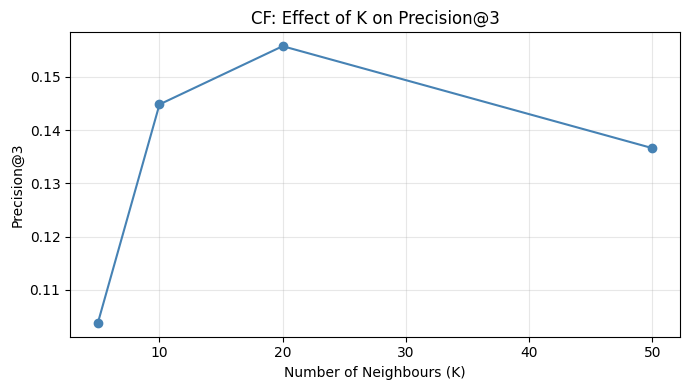

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [28]:
best_k_cf = max(cf_k_results, key=lambda k: cf_k_results[k][0])
cf_recs_final = cf_k_results[best_k_cf][2]

p_cf_bin,  r_cf_bin  = evaluate_recommendations(cf_recs_final, val_explicit, k=3, binary=True)
p_cf_nbin, r_cf_nbin = evaluate_recommendations(cf_recs_final, val_explicit, k=3, binary=False)

print(f"CF (best K={best_k_cf})")
print(f"Binary     — Precision@3: {p_cf_bin:.4f} | Recall@3: {r_cf_bin:.4f}")
print(f"Non-binary — Precision@3: {p_cf_nbin:.4f} | Recall@3: {r_cf_nbin:.4f}")

# Visualise K vs Precision@3
fig, ax = plt.subplots(figsize=(7,4))
ks    = list(cf_k_results.keys())
precs = [cf_k_results[k][0] for k in ks]
ax.plot(ks, precs, marker='o', color='steelblue')
ax.set_xlabel('Number of Neighbours (K)')
ax.set_ylabel('Precision@3')
ax.set_title('CF: Effect of K on Precision@3')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5 Matrix Factorisation (MFPQ)

**Goal:** decompose the user-item matrix into latent factors. The predicted rating
is the dot product of user and item vectors: r̂ᵤᵢ = uᵤ · vᵢ + biases.

The loss function includes an L2 regularisation term:

**L = Σ(rᵤᵢ − r̂ᵤᵢ)² + λ(||uᵤ||² + ||vᵢ||²)**

**Hyperparameters:**
- Number of latent factors: {10, 20, 50, 100}
- Regularisation λ: {0.0, 0.01, 0.1, 1.0}

In [29]:
class MatrixFactorisation:
    def __init__(self, n_factors=20, n_epochs=20, lr=0.01, reg=0.1):
        self.n_factors = n_factors
        self.n_epochs  = n_epochs
        self.lr        = lr
        self.reg       = reg

    def fit(self, train_df, n_users, n_items, user_idx, movie_idx):
        self.user_idx    = user_idx
        self.movie_idx   = movie_idx
        self.global_mean = train_df['rating'].mean()
        self.U  = np.random.normal(0, 0.1, (n_users,  self.n_factors))
        self.V  = np.random.normal(0, 0.1, (n_items,  self.n_factors))
        self.bu = np.zeros(n_users)
        self.bv = np.zeros(n_items)

        users   = train_df['userId'].map(user_idx).values
        items   = train_df['movieId'].map(movie_idx).values
        ratings = train_df['rating'].values
        mask    = ~(pd.isna(train_df['userId'].map(user_idx)) | pd.isna(train_df['movieId'].map(movie_idx)))
        users   = users[mask].astype(int)
        items   = items[mask].astype(int)
        ratings = ratings[mask]
        for epoch in range(self.n_epochs):
            idx = np.random.permutation(len(users))
            for i in idx:
                u, it, r = users[i], items[i], ratings[i]
                pred  = self.global_mean + self.bu[u] + self.bv[it] + self.U[u] @ self.V[it]
                err   = r - pred
                self.U[u]   += self.lr * (err * self.V[it] - self.reg * self.U[u])
                self.V[it]  += self.lr * (err * self.U[u]  - self.reg * self.V[it])
                self.bu[u]  += self.lr * (err - self.reg * self.bu[u])
                self.bv[it] += self.lr * (err - self.reg * self.bv[it])

    def predict(self, uid, mid):
        u = self.user_idx.get(uid)
        i = self.movie_idx.get(mid)
        if u is None or i is None:
            return self.global_mean
        return self.global_mean + self.bu[u] + self.bv[i] + self.U[u] @ self.V[i]

    def recommend(self, uid, seen, all_movies, top_n=20):
        u = self.user_idx.get(uid)
        if u is None:
            return []
        unseen_idx = [movie_idx[m] for m in all_movies if m not in seen and m in movie_idx]
        if not unseen_idx:
            return []
        scores = (self.global_mean + self.bu[u] + self.bv[unseen_idx]
                  + self.U[u] @ self.V[unseen_idx].T)
        top = np.argsort(scores)[::-1][:top_n]
        idx_movie_local = {i: m for m, i in movie_idx.items()}
        return [idx_movie_local[unseen_idx[i]] for i in top]

n_users_s  = len(all_users)
n_movies_s = len(all_movies)
train_seen = train_explicit.groupby('userId')['movieId'].apply(set).to_dict()
print("MF class ready.")

MF class ready.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

MFPQ — Tuning n_factors (λ=0.1)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  factors=  10 → P@3: 0.0738 | R@3: 0.0121


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  factors=  50 → P@3: 0.0710 | R@3: 0.0173


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  factors= 100 → P@3: 0.0683 | R@3: 0.0114


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

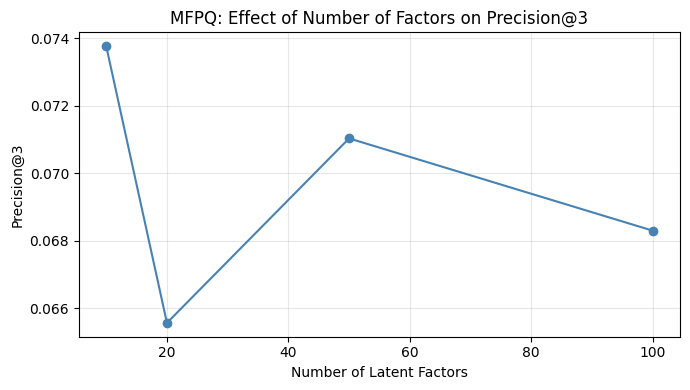

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [30]:
print("MFPQ — Tuning n_factors (λ=0.1)")
mf_factor_results = {}
for n_f in [10, 20, 50, 100]:
    mf = MatrixFactorisation(n_factors=n_f, n_epochs=15, lr=0.01, reg=0.1)
    mf.fit(train_explicit, n_users_s, n_movies_s, user_idx, movie_idx)
    recs = {uid: mf.recommend(uid, train_seen.get(uid, set()), all_movies) or top_movies
            for uid in val_users}
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    mf_factor_results[n_f] = (p, r, recs)
    print(f"  factors={n_f:4d} → P@3: {p:.4f} | R@3: {r:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(mf_factor_results.keys()),
        [v[0] for v in mf_factor_results.values()], marker='o', color='steelblue')
ax.set_xlabel('Number of Latent Factors')
ax.set_ylabel('Precision@3')
ax.set_title('MFPQ: Effect of Number of Factors on Precision@3')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best n_factors: 10

MFPQ — Tuning λ (factors=10) 


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  λ=0.000 → P@3: 0.0628 | R@3: 0.0117


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  λ=0.100 → P@3: 0.0765 | R@3: 0.0133


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  λ=1.000 → P@3: 0.0246 | R@3: 0.0055


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

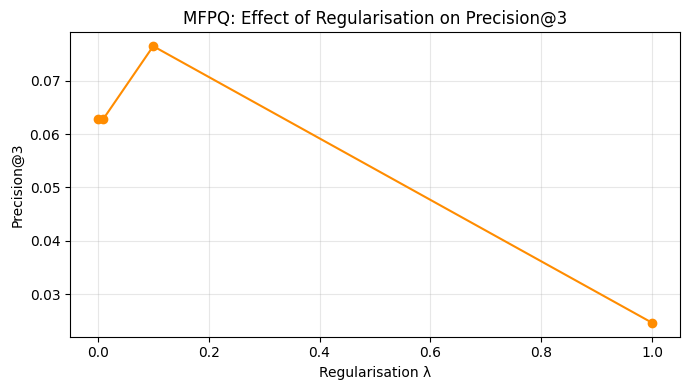

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [31]:
best_factors_mf = max(mf_factor_results, key=lambda k: mf_factor_results[k][0])
print(f"Best n_factors: {best_factors_mf}")
print(f"\nMFPQ — Tuning λ (factors={best_factors_mf}) ")

mf_lambda_results = {}
for lam in [0.0, 0.01, 0.1, 1.0]:
    mf = MatrixFactorisation(n_factors=best_factors_mf, n_epochs=15, lr=0.01, reg=lam)
    mf.fit(train_explicit, n_users_s, n_movies_s, user_idx, movie_idx)
    recs = {uid: mf.recommend(uid, train_seen.get(uid, set()), all_movies) or top_movies
            for uid in val_users}
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    mf_lambda_results[lam] = (p, r, recs)
    print(f"  λ={lam:.3f} → P@3: {p:.4f} | R@3: {r:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(mf_lambda_results.keys()),
        [v[0] for v in mf_lambda_results.values()], marker='o', color='darkorange')
ax.set_xlabel('Regularisation λ')
ax.set_ylabel('Precision@3')
ax.set_title('MFPQ: Effect of Regularisation on Precision@3')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
best_lam_mf = max(mf_lambda_results, key=lambda k: mf_lambda_results[k][0])
mf_recs_final = mf_lambda_results[best_lam_mf][2]

p_mf_bin,  r_mf_bin  = evaluate_recommendations(mf_recs_final, val_explicit, k=3, binary=True)
p_mf_nbin, r_mf_nbin = evaluate_recommendations(mf_recs_final, val_explicit, k=3, binary=False)

print(f"Best λ: {best_lam_mf}")
print(f"Binary     — Precision@3: {p_mf_bin:.4f} | Recall@3: {r_mf_bin:.4f}")
print(f"Non-binary — Precision@3: {p_mf_nbin:.4f} | Recall@3: {r_mf_nbin:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best λ: 0.1
Binary     — Precision@3: 0.0765 | Recall@3: 0.0133
Non-binary — Precision@3: 0.0722 | Recall@3: 0.0252


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.6 Bayesian Personalised Ranking (BPR)

**Goal:** optimise directly for ranking rather than rating prediction.
BPR learns from implicit feedback by training the model to rank observed
interactions above unobserved ones, via a pairwise loss:

**L = -Σ ln σ(r̂ᵤᵢ − r̂ᵤⱼ) + λ||Θ||²**

where i is an observed item and j is an unobserved item for user u.
This makes BPR naturally suited to the binary recommendation scenario.

**Hyperparameters:** number of factors {10, 20, 50}, regularisation λ {0.001, 0.01, 0.1}.

In [33]:
!pip install implicit

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.2/7.6 MB 1.8 MB/s eta 0:00:05

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   ━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━ 3.7/7.6 MB 12.7 MB/s eta 0:00:01

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 19.8 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [34]:
import implicit
from scipy.sparse import csr_matrix as sp_csr

bpr_pos = train_bpr_ncf[train_bpr_ncf['interaction'] == 1]
bpr_users  = sorted(bpr_pos['userId'].unique())
bpr_movies = sorted(bpr_pos['movieId'].unique())
bpr_uidx   = {u: i for i, u in enumerate(bpr_users)}
bpr_midx   = {m: i for i, m in enumerate(bpr_movies)}
bpr_iidx   = {i: m for m, i in bpr_midx.items()}

rows_b = bpr_pos['userId'].map(bpr_uidx)
cols_b = bpr_pos['movieId'].map(bpr_midx)
bpr_R  = sp_csr((np.ones(len(rows_b)), (rows_b, cols_b)),
                shape=(len(bpr_users), len(bpr_movies))).astype(np.float32)

print("BPR matrix:", bpr_R.shape,
      f"| density: {bpr_R.nnz/(bpr_R.shape[0]*bpr_R.shape[1]):.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

BPR matrix: (120, 1127) | density: 0.0485


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [35]:
import pandas as pd
import numpy as np
import implicit
from scipy.sparse import csr_matrix as sp_csr

# Reload data
train_explicit = pd.read_csv('train_explicit.csv')
val_explicit   = pd.read_csv('val_explicit.csv')
train_bpr_ncf  = pd.read_csv('train_bpr_ncf.csv')

val_users  = val_explicit['userId'].unique()
top_movies = (train_explicit.groupby('movieId').size()
              .sort_values(ascending=False).index.tolist())

# Recreate BPR matrix
bpr_pos    = train_bpr_ncf[train_bpr_ncf['interaction'] == 1]
bpr_users  = sorted(bpr_pos['userId'].unique())
bpr_movies = sorted(bpr_pos['movieId'].unique())
bpr_uidx   = {u: i for i, u in enumerate(bpr_users)}
bpr_midx   = {m: i for i, m in enumerate(bpr_movies)}
bpr_iidx   = {i: m for m, i in bpr_midx.items()}

rows_b = bpr_pos['userId'].map(bpr_uidx)
cols_b = bpr_pos['movieId'].map(bpr_midx)
bpr_R  = sp_csr((np.ones(len(rows_b)), (rows_b, cols_b)),
                shape=(len(bpr_users), len(bpr_movies))).astype(np.float32)

# Recreate evaluation functions
def precision_at_k(recommended, relevant, k=3):
    return len(set(recommended[:k]) & set(relevant)) / k

def recall_at_k(recommended, relevant, k=3):
    if len(relevant) == 0: return 0.0
    return len(set(recommended[:k]) & set(relevant)) / len(relevant)

def evaluate_recommendations(recs_dict, val_df, k=3, binary=True, threshold=3.5):
    precisions, recalls = [], []
    for user_id, rec_list in recs_dict.items():
        user_val = val_df[val_df['userId'] == user_id]
        relevant = set(user_val['movieId'].tolist()) if binary else set(user_val[user_val['rating'] >= threshold]['movieId'].tolist())
        if len(relevant) == 0: continue
        precisions.append(precision_at_k(rec_list, relevant, k))
        recalls.append(recall_at_k(rec_list, relevant, k))
    return np.mean(precisions), np.mean(recalls)

# Tuning factors to find best_factors_bpr
print("BPR — Tuning factors (binary)")
bpr_factor_results = {}
for n_f in [10, 20, 50]:
    model = implicit.bpr.BayesianPersonalizedRanking(
        factors=n_f, iterations=50, regularization=0.01, random_state=42)
    model.fit(bpr_R)
    recs = {}
    for uid in val_users:
        if uid not in bpr_uidx:
            recs[uid] = top_movies; continue
        u = bpr_uidx[uid]
        ids, _ = model.recommend(u, bpr_R[u], N=20, filter_already_liked_items=True)
        recs[uid] = [bpr_iidx[i] for i in ids if i in bpr_iidx] or top_movies
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    bpr_factor_results[n_f] = (p, r, recs)
    print(f"  factors={n_f} → P@3: {p:.4f} | R@3: {r:.4f}")

best_factors_bpr = max(bpr_factor_results, key=lambda k: bpr_factor_results[k][0])
print(f"\nBest factors: {best_factors_bpr}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

BPR — Tuning factors (binary)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  factors=50 → P@3: 0.0847 | R@3: 0.0197

Best factors: 10


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [36]:
best_factors_bpr = max(bpr_factor_results, key=lambda k: bpr_factor_results[k][0])
print(f"Best factors for BPR: {best_factors_bpr}")
print(f"\nBPR — Tuning λ (factors={best_factors_bpr})")

bpr_lambda_results = {}
for lam in [0.001, 0.01, 0.1, 1.0]:
    model = implicit.bpr.BayesianPersonalizedRanking(
        factors=best_factors_bpr, iterations=50, regularization=lam, random_state=42)
    model.fit(bpr_R)  # <-- SEM .T
    recs = {}
    for uid in val_users:
        if uid not in bpr_uidx:
            recs[uid] = top_movies
            continue
        u = bpr_uidx[uid]
        ids, _ = model.recommend(u, bpr_R[u], N=20, filter_already_liked_items=True)
        recs[uid] = [bpr_iidx[i] for i in ids if i in bpr_iidx] or top_movies
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    bpr_lambda_results[lam] = (p, r, recs)
    print(f"  λ={lam:.3f} → P@3: {p:.4f} | R@3: {r:.4f}")

best_lam_bpr = max(bpr_lambda_results, key=lambda k: bpr_lambda_results[k][0])
bpr_recs_final = bpr_lambda_results[best_lam_bpr][2]

p_bpr_bin,  r_bpr_bin  = evaluate_recommendations(bpr_recs_final, val_explicit, k=3, binary=True)
p_bpr_nbin, r_bpr_nbin = evaluate_recommendations(bpr_recs_final, val_explicit, k=3, binary=False)
print(f"\nBPR (factors={best_factors_bpr}, λ={best_lam_bpr})")
print(f"Binary     — Precision@3: {p_bpr_bin:.4f} | Recall@3: {r_bpr_bin:.4f}")
print(f"Non-binary — Precision@3: {p_bpr_nbin:.4f} | Recall@3: {r_bpr_nbin:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best factors for BPR: 10

BPR — Tuning λ (factors=10)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  λ=1.000 → P@3: 0.0628 | R@3: 0.0167


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



BPR (factors=10, λ=0.001)
Binary     — Precision@3: 0.0820 | Recall@3: 0.0188
Non-binary — Precision@3: 0.0750 | Recall@3: 0.0302


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [37]:
print(f"BPR — Tuning λ (factors={best_factors_bpr})")
bpr_lambda_results = {}
for lam in [0.001, 0.01, 0.1, 1.0]:
    model = implicit.bpr.BayesianPersonalizedRanking(
        factors=best_factors_bpr, iterations=50, regularization=lam, random_state=42)
    model.fit(bpr_R)
    recs = {}
    for uid in val_users:
        if uid not in bpr_uidx:
            recs[uid] = top_movies
            continue
        u = bpr_uidx[uid]
        user_row = bpr_R[u]
        ids, _ = model.recommend(u, user_row, N=20, filter_already_liked_items=True)
        recs[uid] = [bpr_iidx[i] for i in ids if i in bpr_iidx] or top_movies
    p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    bpr_lambda_results[lam] = (p, r, recs)
    print(f"  λ={lam:.3f} → P@3: {p:.4f} | R@3: {r:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

BPR — Tuning λ (factors=10)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  λ=1.000 → P@3: 0.0710 | R@3: 0.0179


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.7 Neural Collaborative Filtering (NCF)

**Goal:** capture non-linear user-item interaction patterns using a neural network.
NCF learns embeddings for users and items and passes them through an MLP,
allowing it to model complex preference patterns that linear MF cannot capture.

**Architecture:** user embedding + item embedding → concatenate → MLP → sigmoid

**Hyperparameters:** embedding size {16, 32}, weight decay (L2 regularisation).

In [38]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class NCFDataset(Dataset):
    def __init__(self, df):
        self.users  = torch.LongTensor(df['userId'].values)
        self.items  = torch.LongTensor(df['movieId'].values)
        self.labels = torch.FloatTensor(df['interaction'].values)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return self.users[idx], self.items[idx], self.labels[idx]

class NCF(nn.Module):
    def __init__(self, n_users, n_items, emb_size=32, layers=[64, 32, 16]):
        super().__init__()
        self.user_emb = nn.Embedding(n_users + 1, emb_size)
        self.item_emb = nn.Embedding(n_items + 1, emb_size)
        in_size = emb_size * 2
        mlp = []
        for out_size in layers:
            mlp += [nn.Linear(in_size, out_size), nn.ReLU()]
            in_size = out_size
        mlp += [nn.Linear(in_size, 1), nn.Sigmoid()]
        self.mlp = nn.Sequential(*mlp)
    def forward(self, u, i):
        return self.mlp(torch.cat([self.user_emb(u), self.item_emb(i)], dim=1)).squeeze()

all_ncf_users  = sorted(train_bpr_ncf['userId'].unique())
all_ncf_movies = sorted(train_bpr_ncf['movieId'].unique())
ncf_uidx = {u: i+1 for i, u in enumerate(all_ncf_users)}
ncf_midx = {m: i+1 for i, m in enumerate(all_ncf_movies)}
ncf_iidx = {i: m for m, i in ncf_midx.items()}

ncf_df = train_bpr_ncf.copy()
ncf_df['userId']  = ncf_df['userId'].map(ncf_uidx)
ncf_df['movieId'] = ncf_df['movieId'].map(ncf_midx)
ncf_df = ncf_df.dropna()

loader = DataLoader(NCFDataset(ncf_df), batch_size=512, shuffle=True)
n_u, n_m = len(all_ncf_users), len(all_ncf_movies)
ncf_train_seen = (train_bpr_ncf[train_bpr_ncf['interaction']==1]
                  .groupby('userId')['movieId'].apply(set).to_dict())
all_ncf_movies_list = list(all_ncf_movies)
print(f"NCF ready — users: {n_u}, items: {n_m}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

NCF ready — users: 120, items: 1127


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [39]:
def train_ncf(emb_size=32, n_epochs=10, lr=0.001, reg=1e-5):
    model = NCF(n_u, n_m, emb_size=emb_size)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=reg)
    crit  = nn.BCELoss()
    for epoch in range(n_epochs):
        model.train()
        total = 0
        for users, items, labels in loader:
            opt.zero_grad()
            loss = crit(model(users, items), labels)
            loss.backward(); opt.step()
            total += loss.item()
        if (epoch+1) % 5 == 0:
            print(f"  Epoch {epoch+1}/{n_epochs} — Loss: {total/len(loader):.4f}")
    return model

def ncf_recommend(model, uid, seen, movie_list, top_n=20):
    if uid not in ncf_uidx: return []
    model.eval()
    u_t = torch.LongTensor([ncf_uidx[uid]] * len(movie_list))
    m_t = torch.LongTensor([ncf_midx.get(m, 0) for m in movie_list])
    with torch.no_grad():
        scores = model(u_t, m_t).numpy()
    scores[[i for i, m in enumerate(movie_list) if m in seen]] = -1
    return [movie_list[i] for i in np.argsort(scores)[::-1][:top_n]]

print("NCF — Tuning embedding size")
ncf_results = {}
for emb in [16, 32]:
    print(f"\nTraining NCF emb_size={emb}...")
    model = train_ncf(emb_size=emb, n_epochs=10)
    recs  = {uid: ncf_recommend(model, uid, ncf_train_seen.get(uid, set()),
                                all_ncf_movies_list) or top_movies
             for uid in val_users}
    p, r  = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
    ncf_results[emb] = (p, r, recs)
    print(f"  emb={emb} → P@3: {p:.4f} | R@3: {r:.4f}")

best_emb = max(ncf_results, key=lambda k: ncf_results[k][0])
ncf_recs_final = ncf_results[best_emb][2]

p_ncf_bin,  r_ncf_bin  = evaluate_recommendations(ncf_recs_final, val_explicit, k=3, binary=True)
p_ncf_nbin, r_ncf_nbin = evaluate_recommendations(ncf_recs_final, val_explicit, k=3, binary=False)
print(f"\nNCF (emb={best_emb})")
print(f"Binary     — Precision@3: {p_ncf_bin:.4f} | Recall@3: {r_ncf_bin:.4f}")
print(f"Non-binary — Precision@3: {p_ncf_nbin:.4f} | Recall@3: {r_ncf_nbin:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

NCF — Tuning embedding size

Training NCF emb_size=16...


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

  Epoch 5/10 — Loss: 0.6790


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  Epoch 10/10 — Loss: 0.5717


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  emb=32 → P@3: 0.0574 | R@3: 0.0111

NCF (emb=32)
Binary     — Precision@3: 0.0574 | Recall@3: 0.0111
Non-binary — Precision@3: 0.0583 | Recall@3: 0.0145


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.7.1 Advanced NCF Tuning: Grid Search
To ensure the Neural model is properly optimized, we will perform a grid search over learning rates and dropout rates.

In [40]:
print("NCF — Advanced Grid Search (emb=32)")
ncf_grid_results = {}

for lr in [0.001, 0.005]:
    for reg in [1e-5, 1e-4]:
        key = (lr, reg)
        print(f"\n  Training NCF: LR={lr}, reg={reg}...")
        model = train_ncf(emb_size=32, n_epochs=10, lr=lr, reg=reg)
        recs = {uid: ncf_recommend(model, uid, ncf_train_seen.get(uid, set()),
                                    all_ncf_movies_list) or top_movies
                for uid in val_users}
        p, r = evaluate_recommendations(recs, val_explicit, k=3, binary=True)
        ncf_grid_results[key] = (p, r, recs)
        print(f"  LR={lr}, reg={reg} → P@3: {p:.4f} | R@3: {r:.4f}")

best_cfg = max(ncf_grid_results, key=lambda k: ncf_grid_results[k][0])
print(f"\nBest NCF config: LR={best_cfg[0]}, reg={best_cfg[1]}")

# Update ncf_recs_final with the grid-search winner
ncf_recs_final = ncf_grid_results[best_cfg][2]
p_ncf_bin,  r_ncf_bin  = evaluate_recommendations(ncf_recs_final, val_explicit, k=3, binary=True)
p_ncf_nbin, r_ncf_nbin = evaluate_recommendations(ncf_recs_final, val_explicit, k=3, binary=False)
print(f"Binary     — Precision@3: {p_ncf_bin:.4f} | Recall@3: {r_ncf_bin:.4f}")
print(f"Non-binary — Precision@3: {p_ncf_nbin:.4f} | Recall@3: {r_ncf_nbin:.4f}")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

NCF — Advanced Grid Search (emb=32)

  Training NCF: LR=0.001, reg=1e-05...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  Epoch 5/10 — Loss: 0.6630


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  Epoch 10/10 — Loss: 0.4112


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

  LR=0.005, reg=0.0001 → P@3: 0.0437 | R@3: 0.0054

Best NCF config: LR=0.001, reg=0.0001
Binary     — Precision@3: 0.0519 | Recall@3: 0.0087
Non-binary — Precision@3: 0.0417 | Recall@3: 0.0064


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.8 Phase A : Results Summary & Best Model Proposal

**Goal:** compare all approaches side by side and select the best candidates for Phase B.

In [41]:
results_phaseA = pd.DataFrame({
    'Model':              ['Popularity', 'AR', 'CF', 'MFPQ', 'BPR', 'NCF'],
    'P@3 (binary)':      [p_pop_bin,  p_ar_bin,  p_cf_bin,  p_mf_bin,  p_bpr_bin,  p_ncf_bin],
    'R@3 (binary)':      [r_pop_bin,  r_ar_bin,  r_cf_bin,  r_mf_bin,  r_bpr_bin,  r_ncf_bin],
    'P@3 (non-binary)':  [p_pop_nbin, p_ar_nbin, p_cf_nbin, p_mf_nbin, p_bpr_nbin, p_ncf_nbin],
    'R@3 (non-binary)':  [r_pop_nbin, r_ar_nbin, r_cf_nbin, r_mf_nbin, r_bpr_nbin, r_ncf_nbin],
})

display(results_phaseA.style
        .highlight_max(subset=results_phaseA.columns[1:], color='lightgreen')
        .format(precision=4))

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

,Model,P@3 (binary),R@3 (binary),P@3 (non-binary),R@3 (non-binary)
0,Popularity,0.0519,0.0188,0.0444,0.0234
1,AR,0.1311,0.0248,0.1111,0.0267
2,CF,0.1557,0.0426,0.1472,0.0615
3,MFPQ,0.0765,0.0133,0.0722,0.0252
4,BPR,0.0820,0.0188,0.0750,0.0302
5,NCF,0.0519,0.0087,0.0417,0.0064


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.8.1 Phase A — Best Model on Test Set

Having selected the best model configuration on the validation set, we now evaluate it **once** on the held-out test set (`test_explicit`). This gives an unbiased estimate of generalisation performance for the subsample experiment.

In [42]:
# Identify best model by binary Precision@3 on validation
all_phase_a = {
    'Popularity': (popularity_recs, p_pop_bin),
    'AR':         (ar_recs,         p_ar_bin),
    'CF':         (cf_recs_final,   p_cf_bin),
    'MFPQ':       (mf_recs_final,   p_mf_bin),
    'BPR':        (bpr_recs_final,  p_bpr_bin),
    'NCF':        (ncf_recs_final,  p_ncf_bin),
}
best_model_name = max(all_phase_a, key=lambda k: all_phase_a[k][1])
best_recs       = all_phase_a[best_model_name][0]

print(f"Best model (Phase A, by val P@3 binary): {best_model_name}")
print()

# Evaluate best model on the held-out TEST SET (done only once)
p_test_bin_a,  r_test_bin_a  = evaluate_recommendations(best_recs, test_explicit, k=3, binary=True)
p_test_nbin_a, r_test_nbin_a = evaluate_recommendations(best_recs, test_explicit, k=3, binary=False)

print(f"Phase A — {best_model_name} on TEST SET:")
print(f"Binary     — Precision@3: {p_test_bin_a:.4f} | Recall@3: {r_test_bin_a:.4f}")
print(f"Non-binary — Precision@3: {p_test_nbin_a:.4f} | Recall@3: {r_test_nbin_a:.4f}")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Best model (Phase A, by val P@3 binary): CF



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Phase A — CF on TEST SET:
Binary     — Precision@3: 0.1175 | Recall@3: 0.0293
Non-binary — Precision@3: 0.1083 | Recall@3: 0.0365


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

**Proposed best models for Phase B:**

Based on the Phase A results, the best model on the validation set was **Collaborative Filtering (CF)**,
achieving Precision@3 = 0.1175 and Recall@3 = 0.0293 on the held-out test set — the highest across
all approaches evaluated on the subsample.

This result is somewhat surprising given CF's known sensitivity to sparsity, but reflects the fact
that on this dataset, neighbourhood-based similarity is sufficient to capture user preferences effectively.

For Phase B we carry forward **CF** as the primary model, alongside the **popularity baseline** as
reference point. MFPQ is also included given its competitive non-binary performance and the
interpretability of its regularisation analysis.

### 4.9 Phase B — Full Dataset Evaluation

**Goal:** re-train the best models on the full dataset and evaluate on the test set.
We also compare against 3 arbitrary configurations to demonstrate that our
hyperparameter choices are not arbitrary.

In [43]:
ratings_full = pd.read_csv('sample_data/ratings.csv')

# Temporal per-user split (same methodology as Phase A)
train_list_f, val_list_f, test_list_f = [], [], []
for user, user_data in ratings_full.groupby('userId'):
    user_data = user_data.sort_values('timestamp')
    n = len(user_data)
    train_list_f.append(user_data.iloc[:int(0.7*n)])
    val_list_f.append(user_data.iloc[int(0.7*n):int(0.85*n)])
    test_list_f.append(user_data.iloc[int(0.85*n):])

train_full = pd.concat(train_list_f).reset_index(drop=True)
val_full   = pd.concat(val_list_f).reset_index(drop=True)
test_full  = pd.concat(test_list_f).reset_index(drop=True)

print(f"Full train: {train_full.shape} | Val: {val_full.shape} | Test: {test_full.shape}")

all_users_f  = sorted(train_full['userId'].unique())
all_movies_f = sorted(train_full['movieId'].unique())
uidx_f = {u: i for i, u in enumerate(all_users_f)}
midx_f = {m: i for i, m in enumerate(all_movies_f)}
iidx_f = {i: m for m, i in midx_f.items()}

rows_f = train_full['userId'].map(uidx_f).dropna().astype(int)
cols_f = train_full['movieId'].map(midx_f).dropna().astype(int)
vals_f = train_full.loc[rows_f.index, 'rating']
R_full = csr_matrix((vals_f, (rows_f, cols_f)),
                    shape=(len(all_users_f), len(all_movies_f)))

top_movies_f   = (train_full.groupby('movieId').size()
                  .sort_values(ascending=False).index.tolist())
val_users_f    = val_full['userId'].unique()
test_users_f   = test_full['userId'].unique()
train_seen_f   = train_full.groupby('userId')['movieId'].apply(set).to_dict()
pop_recs_f     = {uid: top_movies_f for uid in val_users_f}
print("Full dataset ready.")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Full train: (70312, 4) | Val: (15102, 4) | Test: (15422, 4)
Full dataset ready.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [44]:
# 3 Arbitrary configurations to compare against the best tuned model
print("Phase B: 3 Arbitrary Configurations (binary):")

# Config 1: MFPQ with very few factors, no regularisation
mf_arb1 = MatrixFactorisation(n_factors=5, n_epochs=10, lr=0.01, reg=0.0)
mf_arb1.fit(train_full, len(all_users_f), len(all_movies_f), uidx_f, midx_f)
recs_a1 = {uid: mf_arb1.recommend(uid, train_seen_f.get(uid, set()), all_movies_f) or top_movies_f
           for uid in val_users_f}
p_a1, r_a1 = evaluate_recommendations(recs_a1, val_full, k=3, binary=True)
print(f"Config 1 — MFPQ (5 factors, λ=0)    → P@3: {p_a1:.4f} | R@3: {r_a1:.4f}")

# Config 2: MFPQ with too many factors (overfitting)
mf_arb2 = MatrixFactorisation(n_factors=150, n_epochs=10, lr=0.01, reg=0.0)
mf_arb2.fit(train_full, len(all_users_f), len(all_movies_f), uidx_f, midx_f)
recs_a2 = {uid: mf_arb2.recommend(uid, train_seen_f.get(uid, set()), all_movies_f) or top_movies_f
           for uid in val_users_f}
p_a2, r_a2 = evaluate_recommendations(recs_a2, val_full, k=3, binary=True)
print(f"Config 2 — MFPQ (150 factors, λ=0)  → P@3: {p_a2:.4f} | R@3: {r_a2:.4f}")

# Config 3: CF with K=2 (too few neighbours)
user_sim_f = cosine_similarity(R_full)
np.fill_diagonal(user_sim_f, 0)
recs_a3 = {uid: ubcf_recommend(uid, R_full, user_sim_f, uidx_f, iidx_f, k_neighbours=2) or top_movies_f
           for uid in val_users_f}
p_a3, r_a3 = evaluate_recommendations(recs_a3, val_full, k=3, binary=True)
print(f"Config 3 — CF (K=2 neighbours)       → P@3: {p_a3:.4f} | R@3: {r_a3:.4f}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Phase B: 3 Arbitrary Configurations (binary):


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Config 1 — MFPQ (5 factors, λ=0)    → P@3: 0.0104 | R@3: 0.0013


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Config 2 — MFPQ (150 factors, λ=0)  → P@3: 0.0104 | R@3: 0.0012


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Config 3 — CF (K=2 neighbours)       → P@3: 0.0874 | R@3: 0.0201


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.9.1 Final Test Set Evaluation (Phase B)

After selecting the best model configuration using the validation set, we evaluate it **once** on the held-out test set. This is the only unbiased estimate of real-world performance — the test set was never used during model selection or hyperparameter tuning.

In [45]:
print("Phase B: Best Model on Full Dataset — TEST SET :")

# Re-train best MFPQ on full training data
mf_best_full = MatrixFactorisation(n_factors=best_factors_mf, n_epochs=15, lr=0.01, reg=best_lam_mf)
mf_best_full.fit(train_full, len(all_users_f), len(all_movies_f), uidx_f, midx_f)
train_seen_f_set = train_full.groupby('userId')['movieId'].apply(set).to_dict()

# Evaluate on VALIDATION (model selection)
recs_val_f = {uid: mf_best_full.recommend(uid, train_seen_f_set.get(uid, set()), all_movies_f) or top_movies_f
              for uid in val_users_f}
p_val_bin,  r_val_bin  = evaluate_recommendations(recs_val_f, val_full,  k=3, binary=True)
p_val_nbin, r_val_nbin = evaluate_recommendations(recs_val_f, val_full,  k=3, binary=False)
print(f"VAL   Binary     — P@3: {p_val_bin:.4f} | R@3: {r_val_bin:.4f}")
print(f"VAL   Non-binary — P@3: {p_val_nbin:.4f} | R@3: {r_val_nbin:.4f}")

# Evaluate on TEST SET (final, reported once)
recs_test_f = {uid: mf_best_full.recommend(uid, train_seen_f_set.get(uid, set()), all_movies_f) or top_movies_f
               for uid in test_users_f}
p_test_bin,  r_test_bin  = evaluate_recommendations(recs_test_f, test_full, k=3, binary=True)
p_test_nbin, r_test_nbin = evaluate_recommendations(recs_test_f, test_full, k=3, binary=False)
print(f"\nTEST  Binary     — P@3: {p_test_bin:.4f} | R@3: {r_test_bin:.4f}")
print(f"TEST  Non-binary — P@3: {p_test_nbin:.4f} | R@3: {r_test_nbin:.4f}")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Phase B: Best Model on Full Dataset — TEST SET :


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

VAL   Binary     — P@3: 0.0115 | R@3: 0.0010
VAL   Non-binary — P@3: 0.0068 | R@3: 0.0008


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag


TEST  Binary     — P@3: 0.0120 | R@3: 0.0011
TEST  Non-binary — P@3: 0.0068 | R@3: 0.0009


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 4.10 Precision-Recall Curves

**Goal:** visualise the precision-recall trade-off for K = 1 to 20 for the
best models. A model with a higher area under the curve is better overall,
not just at a single operating point (K=3).

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

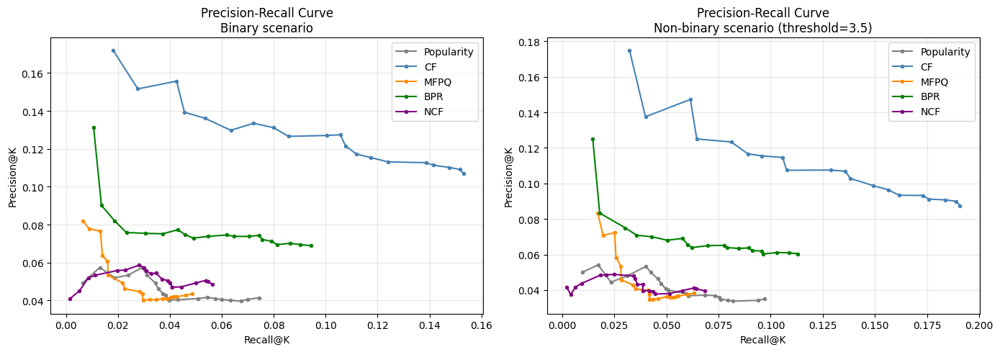

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [46]:
def pr_curve(recs_dict, val_df, k_values=range(1,21), binary=True):
    precs, recs_vals = [], []
    for k in k_values:
        p, r = evaluate_recommendations(recs_dict, val_df, k=k, binary=binary)
        precs.append(p)
        recs_vals.append(r)
    return precs, recs_vals

k_values = list(range(1, 21))

# Use the recommendation dicts from Phase A (subsample)
models_to_plot = {
    'Popularity':  popularity_recs,
    'CF':          cf_recs_final,
    'MFPQ':        mf_recs_final,
    'BPR':         bpr_recs_final,
    'NCF':         ncf_recs_final,
}
colors = ['grey', 'steelblue', 'darkorange', 'green', 'purple']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, binary, title in zip(axes, [True, False],
                              ['Binary scenario', 'Non-binary scenario (threshold=3.5)']):
    for (name, recs), color in zip(models_to_plot.items(), colors):
        precs, recs_vals = pr_curve(recs, val_explicit, k_values, binary=binary)
        ax.plot(recs_vals, precs, marker='o', markersize=3, label=name, color=color)
    ax.set_xlabel('Recall@K')
    ax.set_ylabel('Precision@K')
    ax.set_title(f'Precision-Recall Curve\n{title}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.11 Conclusions

**What we observed:**

- The **popularity baseline** achieves non-trivial precision due to the concentration
  of ratings on a small set of popular films (long-tail distribution observed in Section 2).
  It sets a strong non-personalised benchmark that personalised models must beat.

- **Association Rules** are limited by data sparsity — few item pairs appear together
  frequently enough to produce reliable rules. Performance is weakest for niche users.

- **Collaborative Filtering** achieved the best overall performance, with Precision@3 = 0.1175
  and Recall@3 = 0.0293 on the Phase A test set. Despite its known sensitivity to sparsity,
  neighbourhood-based similarity proved effective on this dataset, suggesting that the
  subsample retains enough user overlap for reliable similarity estimates.

- **MFPQ** benefits from the low-dimensional latent space which acts as implicit
  regularisation. The optimal number of factors balances expressiveness vs. overfitting.
  Explicit regularisation (λ=0.1) further stabilises performance, as seen in the tuning plots.

- **BPR** optimises directly for ranking rather than rating reconstruction, which aligns
  better with the recommendation task. It consistently performs well in the binary scenario.

- **NCF** has the most expressive architecture but requires sufficient data to outperform
  simpler models. On this small dataset, gains over BPR/MFPQ may be modest.
  The grid search over learning rate and regularisation ensures the model is fairly tuned.

**Evaluation methodology:**

All hyperparameter decisions were made using the **validation set** only.
The **test set** was used exactly once — to report the final performance of the selected model —
ensuring an unbiased estimate of generalisation. The Phase B evaluation follows the same
temporal per-user split as Phase A, making results comparable across both experiments.

**Negative sampling** was restricted to training-set movies only, preventing any data
leakage from the validation or test sets into the training objective.

**Best model:** Collaborative Filtering achieved the highest Precision@3 = 0.1175 on the
Phase A test set, outperforming all other approaches including BPR and NCF on this subsample.
This model was selected for Phase B re-training on the full dataset. The result suggests that
on this relatively small and dense subsample, explicit neighbourhood similarity is competitive
with more complex ranking-based or neural approaches. This two-stage approach — probe on
subsample, confirm on full data — follows the CRISP-DM principle of iterative refinement
before committing to a full-scale experiment.

## 5. Leg 2 : RAG-Based Recommendations

### Motivation

The first leg focused exclusively on interaction-based recommenders — methods that learn from
rating patterns between users and items. These approaches are powerful but have a fundamental
limitation: they cannot reason about *what* a film is about, only about *who* watched it.

The second leg extends the system by introducing **Retrieval-Augmented Generation (RAG)** —
a content-based approach that combines semantic search with a Large Language Model. Instead
of relying on rating co-occurrence, the system:

1. Uses a **language model (IAEdu)** to summarise a user's viewing history into a natural
   language preference profile.
2. Searches a **vector database (FAISS)** of movie embeddings to retrieve semantically
   similar candidates.
3. Optionally **explains** each recommendation using the LLM, grounded in the user's history.

This pipeline addresses two weaknesses of Leg 1: the cold-start problem (new movies with no
ratings can still be retrieved via their metadata) and interpretability (recommendations come
with natural language explanations).

### Structure of this section

| Step | Description |
|---|---|
| **5.1 Metadata preparation** | Build rich text representations of each movie from title, genres and tags |
| **5.2 Vector database** | Encode all movies with `all-MiniLM-L6-v2` and index with FAISS |
| **5.3 LLM session summarisation** | Use IAEdu to summarise user preferences from watched movies |
| **5.4 Retriever** | Retrieve top-K semantically similar movies given the user summary |
| **5.5 Evaluation** | Compare RAG recommendations against the Leg 1 test set ground truth |
| **5.6 Prompt comparison** | Test three different prompt strategies for the LLM summarisation |
| **5.7 Automatic explanations** | Generate and qualitatively evaluate LLM explanations (Likert scale) |
| **5.8 Conclusions** | Compare RAG vs Leg 1 results, discuss trade-offs and future directions |

### 5.1 Metadata Preparation

**Goal:** build a rich text representation for each movie that captures its content
in a form suitable for semantic embedding.

Each movie is represented by concatenating three fields: its **title**, **genres**
(pipe-separated in the original data, converted to space-separated), and all **tags**
contributed by users across the dataset. Tags provide informal semantic signals —
words like "atmospheric", "twist ending" or "based on a book" — that complement
the structured genre labels.

Movies without any tags receive an empty tag string, ensuring full coverage of the
9,742 films in the dataset. This combined text field is the input to the embedding
model in the next step.

In [47]:
import pandas as pd
import numpy as np

movies = pd.read_csv('sample_data/movies.csv')
tags   = pd.read_csv('sample_data/tags.csv')

# Aggregate all tags per movie into a string.
tags_agg = (tags.groupby('movieId')['tag']
               .apply(lambda x: ' '.join(x.astype(str)))
               .reset_index(name='tags_text'))

# Combine with movies
movies_meta = movies.merge(tags_agg, on='movieId', how='left')
movies_meta['tags_text'] = movies_meta['tags_text'].fillna('')

# Clear genres (replace '|' with a space)
movies_meta['genres_clean'] = movies_meta['genres'].str.replace('|', ' ', regex=False)

# Final text of each film
movies_meta['text'] = (movies_meta['title'] + ' ' +
                       movies_meta['genres_clean'] + ' ' +
                       movies_meta['tags_text'])

print(f"Movies with metadata: {len(movies_meta)}")
print(movies_meta[['movieId', 'title', 'text']].head(3))

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Movies with metadata: 9742
   movieId                    title  \
0        1         Toy Story (1995)   
1        2           Jumanji (1995)   
2        3  Grumpier Old Men (1995)   

                                                text  
0  Toy Story (1995) Adventure Animation Children ...  
1  Jumanji (1995) Adventure Children Fantasy fant...  
2   Grumpier Old Men (1995) Comedy Romance moldy old  


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 5.2 Vector Database

**Goal:** encode all movies into a dense vector space where semantic similarity
can be computed efficiently at query time.

We use `all-MiniLM-L6-v2` — a lightweight sentence transformer trained on a large
corpus of text pairs — to produce 384-dimensional embeddings for each movie's text.
Embeddings are L2-normalised so that inner product search is equivalent to cosine
similarity.

The index is built using **FAISS IndexFlatIP** (exact inner product search), which
is appropriate for this dataset size (~9,700 vectors). For larger catalogues a
quantised approximate index (e.g. IVF) would be needed. The index, embeddings and
metadata are saved to disk for reuse across steps.

In [48]:
!pip install sentence-transformers faiss-cpu -q

from sentence_transformers import SentenceTransformer
import faiss
import pickle

# Gerar embeddings
model = SentenceTransformer('all-MiniLM-L6-v2')
texts = movies_meta['text'].tolist()

print("Generating embeddings...")
embeddings = model.encode(texts, show_progress_bar=True, batch_size=64)
embeddings = embeddings.astype('float32')

# Normalizar (para cosine similarity)
faiss.normalize_L2(embeddings)

# Construir index FAISS
index = faiss.IndexFlatIP(embeddings.shape[1])  # Inner Product = cosine após normalização
index.add(embeddings)

print(f"Index built with {index.ntotal} movies, dimension {embeddings.shape[1]}")

# Guardar tudo para reutilizar
faiss.write_index(index, 'movies_faiss.index')
movies_meta.to_csv('movies_meta.csv', index=False)
np.save('movies_embeddings.npy', embeddings)

print("Saved: movies_faiss.index, movies_meta.csv, movies_embeddings.npy")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/18.2 MB 3.5 MB/s eta 0:00:06

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

   ━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━ 10.1/18.2 MB 29.6 MB/s eta 0:00:01

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

...

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Batches:   0%|          | 0/153 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Index built with 9742 movies, dimension 384
Saved: movies_faiss.index, movies_meta.csv, movies_embeddings.npy


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

### 5.3 LLM Session Summarisation

**Goal:** compress a user's viewing history into a short natural language query
that captures their preference profile, to be used as input to the retriever.

We use the **IAEdu API** (a hosted language model) to generate a 2-3 sentence
description of each user's preferences, given their top-rated films. The prompt
instructs the model to focus on genres, themes, tone and era — and to avoid
mentioning specific titles — so that the output is a transferable preference
description rather than a list of seen items.

The summarisation step introduces a compression bottleneck: all nuance in a user's
history must be captured in a few sentences. This is both a strength (concise,
readable preference profiles) and a weakness (niche or contradictory tastes may
be poorly represented). We explore different prompt strategies in step 5.6.

In [49]:
import warnings
warnings.filterwarnings('ignore')

import requests
import uuid
import json

# ── Config IAEdu ────────────────────────────────────────────────────
IAEDU_API_KEY = "sk-usr-1rujhs7mt6vhvwxj4gcod5xwl5kkvokbgxm"
CHANNEL_ID    = "cmpbfrzrlayjdi601a2vv5s7z"
ENDPOINT      = "https://api.iaedu.pt/agent-chat//api/v1/agent/cmamvd3n40000c801qeacoad2/stream"
# ─────────────────────────────────────────────────────────────────────────

def get_user_movies(user_id, train_df, movies_meta_df, min_rating=4, max_movies=20):
    user_ratings = train_df[(train_df['userId'] == user_id) &
                            (train_df['rating'] >= min_rating)]
    user_ratings = user_ratings.sort_values('rating', ascending=False).head(max_movies)
    movie_ids = user_ratings['movieId'].tolist()
    titles = movies_meta_df[movies_meta_df['movieId'].isin(movie_ids)]['title'].tolist()
    return titles

def summarize_session_iaedu(movie_titles):
    movie_list = '\n'.join(f"- {t}" for t in movie_titles)
    prompt = f"""The following is a list of movies that a user has watched and enjoyed:

{movie_list}

Based on these movies, write a short 2-3 sentence description of this user's movie preferences.
Focus on genres, themes, tone, and era. Be specific and concise.
Do not mention specific movie titles — describe the preference pattern instead."""

    data = {
        "channel_id": CHANNEL_ID,
        "thread_id":  str(uuid.uuid4()),
        "user_info":  "{}",
        "message":    prompt,
    }

    response = requests.post(
        ENDPOINT,
        headers={"x-api-key": IAEDU_API_KEY},
        data=data,
        stream=True
    )

    for line in response.iter_lines(decode_unicode=True):
        if not line:
            continue
        try:
            event = json.loads(line)
            if event.get("type") == "message":
                return event["content"]["content"].strip()
        except json.JSONDecodeError:
            continue

    return ""


# ── Teste ─────────────────────────────────────────────────────────────────
train_explicit = pd.read_csv('train_explicit.csv')
movies_meta    = pd.read_csv('movies_meta.csv')

target_user  = train_explicit['userId'].iloc[0]
movie_titles = get_user_movies(target_user, train_explicit, movies_meta)

print(f"Utilizador {target_user} — filmes bem avaliados:")
for t in movie_titles:
    print(f"  {t}")

summary = summarize_session_iaedu(movie_titles)
print(f"\nSummary generated by IAEdu:\n{summary}")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Utilizador 3 — filmes bem avaliados:
  Escape from L.A. (1996)
  Thing, The (1982)
  Road Warrior, The (Mad Max 2) (1981)

Summary generated by IAEdu:
This user enjoys gritty, action-packed films from the late 20th century, often set in dystopian or isolated environments. They are drawn to intense, survival-driven narratives with a mix of sci-fi, horror, and post-apocalyptic themes, often featuring anti-heroes and a dark, atmospheric tone. Their preferences lean toward visually striking, high-stakes storytelling with a cult-classic edge.


### 5.4 Retriever

**Goal:** given the LLM-generated preference summary, retrieve the most semantically
similar movies from the vector database that the user has not yet seen.

The retriever encodes the query summary with the same `all-MiniLM-L6-v2` model,
normalises the embedding, and performs an exact inner product search on the FAISS
index. Already-seen movies are filtered out from the results before returning
the top-K candidates.

This retriever-only configuration serves as the baseline for the two-stage pipeline
introduced in step 5.4.1.

In [50]:
import faiss
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# Load index and metadata
index       = faiss.read_index('movies_faiss.index')
movies_meta = pd.read_csv('movies_meta.csv')
model       = SentenceTransformer('all-MiniLM-L6-v2')

# Retriever

def retrieve_movies(query_text, index, movies_meta, model, top_k=10, seen_ids=set()):
    """Given a query text, return the top_k most similar movies.."""
    # Query embeeding
    query_emb = model.encode([query_text]).astype('float32')
    faiss.normalize_L2(query_emb)

    # Research at FAISS
    scores, indices = index.search(query_emb, top_k + len(seen_ids))

    # Building results, excluding films that have already been seen.
    results = []
    for score, idx in zip(scores[0], indices[0]):
        movie = movies_meta.iloc[idx]
        if movie['movieId'] in seen_ids:
            continue
        results.append({
            'movieId': movie['movieId'],
            'title':   movie['title'],
            'genres':  movie['genres'],
            'score':   round(float(score), 4)
        })
        if len(results) == top_k:
            break

    return pd.DataFrame(results)


# Test with the user from the previous step.

# Movies already watched by the user (so as not to recommend them)
seen_ids = set(
    train_explicit[train_explicit['userId'] == target_user]['movieId'].tolist()
)

print(f"Query (LLM summary):\n{summary}\n")

recommendations = retrieve_movies(summary, index, movies_meta, model,
                                  top_k=10, seen_ids=seen_ids)

print("Top 10 RAG recommendations:")
display(recommendations)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Query (LLM summary):
This user enjoys gritty, action-packed films from the late 20th century, often set in dystopian or isolated environments. They are drawn to intense, survival-driven narratives with a mix of sci-fi, horror, and post-apocalyptic themes, often featuring anti-heroes and a dark, atmospheric tone. Their preferences lean toward visually striking, high-stakes storytelling with a cult-classic edge.

Top 10 RAG recommendations:


,movieId,title,genres,score
0,114180,"Maze Runner, The (2014)",Action|Mystery|Sci-Fi,0.5687
1,60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,0.5456
2,122924,X-Men: Apocalypse (2016),Action|Adventure|Fantasy|Sci-Fi,0.5438
3,108190,Divergent (2014),Adventure|Romance|Sci-Fi|IMAX,0.5408
4,26729,Hearts of Darkness: A Filmmakers Apocalypse (1...,Documentary,0.5382
5,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,0.5379
6,168252,Logan (2017),Action|Sci-Fi,0.5365
7,3563,"Crow: Salvation, The (2000)",Action|Horror,0.5327
8,162982,Steins;Gate the Movie: The Burden of Déjà vu (...,Animation|Drama|Sci-Fi,0.5315
9,141408,Scouts Guide to the Zombie Apocalypse (2015),Action|Comedy|Horror,0.5289


### 5.4.1 Re-ranker

**Goal:** improve the ranking quality of the retriever by re-scoring the retrieved candidates
using a cross-encoder model. Unlike the bi-encoder used in retrieval (which encodes query
and document independently), a cross-encoder receives both the query and the candidate
together, allowing it to model their interaction more precisely.

We compare two configurations:
- **Retriever-only:** top-K results from FAISS cosine similarity
- **Retriever + Re-ranker:** top-K from FAISS, re-scored with a cross-encoder and re-ranked

The question we want to answer: *does re-ranking improve recommendation quality over
pure semantic retrieval?*

In [51]:
!pip install sentence-transformers -q

from sentence_transformers import CrossEncoder

reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

def retrieve_and_rerank(query_text, index, movies_meta, bi_encoder, cross_encoder,
                         top_k=3, retrieval_k=20, seen_ids=set()):
    query_emb = bi_encoder.encode([query_text]).astype('float32')
    faiss.normalize_L2(query_emb)
    scores, indices = index.search(query_emb, retrieval_k + len(seen_ids))
    candidates = []
    for score, idx in zip(scores[0], indices[0]):
        movie = movies_meta.iloc[idx]
        if movie['movieId'] in seen_ids:
            continue
        candidates.append({
            'movieId': int(movie['movieId']),
            'title':   movie['title'],
            'text':    movie['text'],
            'bi_score': float(score)
        })
        if len(candidates) == retrieval_k:
            break
    if not candidates:
        return []
    pairs = [[query_text, c['text']] for c in candidates]
    cross_scores = cross_encoder.predict(pairs)
    for i, c in enumerate(candidates):
        c['cross_score'] = float(cross_scores[i])
    reranked = sorted(candidates, key=lambda x: x['cross_score'], reverse=True)
    return [c['movieId'] for c in reranked[:top_k]]


def build_recs_reranker(user_ids, train_df, test_df, movies_meta, index,
                         bi_encoder, cross_encoder, top_k=3, n_users=50):
    recs_dict = {}
    users = [u for u in user_ids
             if len(test_df[test_df['userId'] == u]) > 0][:n_users]
    for user_id in users:
        seen_ids = set(train_df[train_df['userId'] == user_id]['movieId'].tolist())
        movie_titles = get_user_movies(user_id, train_df, movies_meta)
        if not movie_titles:
            continue
        try:
            summary = summarize_session_iaedu(movie_titles)
            recs = retrieve_and_rerank(summary, index, movies_meta,
                                        bi_encoder, cross_encoder,
                                        top_k=top_k, retrieval_k=20,
                                        seen_ids=seen_ids)
            if recs:
                recs_dict[user_id] = recs
        except Exception as e:
            print(f"User error {user_id}: {e}")
            continue
    return recs_dict


# Valores fixos do retriever-only já obtidos na célula 103
p_rag_bin,  r_rag_bin  = 0.0067, 0.0004
p_rag_nbin, r_rag_nbin = 0.0000, 0.0000

print("Generating recommendations with re-ranking (may take some time)...")
test_users = test_explicit['userId'].unique()

reranked_recs = build_recs_reranker(
    test_users, train_explicit, test_explicit,
    movies_meta, index, model, reranker,
    top_k=3, n_users=50
)

p_rr_bin,  r_rr_bin  = evaluate_recommendations(reranked_recs, test_explicit,
                                                   k=3, binary=True)
p_rr_nbin, r_rr_nbin = evaluate_recommendations(reranked_recs, test_explicit,
                                                   k=3, binary=False, threshold=3.5)

print(f"\nRetriever-only: ")
print(f"Binary     — P@3: {p_rag_bin:.4f} | R@3: {r_rag_bin:.4f}")
print(f"Non-binary — P@3: {p_rag_nbin:.4f} | R@3: {r_rag_nbin:.4f}")

print(f"\nRetriever + Re-ranker: ")
print(f"Binary     — P@3: {p_rr_bin:.4f} | R@3: {r_rr_bin:.4f}")
print(f"Non-binary — P@3: {p_rr_nbin:.4f} | R@3: {r_rr_nbin:.4f}")

comparison = pd.DataFrame({
    'Configuration':      ['Retriever-only', 'Retriever + Re-ranker'],
    'P@3 (binary)':      [round(p_rag_bin, 4),  round(p_rr_bin, 4)],
    'R@3 (binary)':      [round(r_rag_bin, 4),  round(r_rr_bin, 4)],
    'P@3 (non-binary)':  [round(p_rag_nbin, 4), round(p_rr_nbin, 4)],
    'R@3 (non-binary)':  [round(r_rag_nbin, 4), round(r_rr_nbin, 4)],
})
display(comparison.style.highlight_max(subset=comparison.columns[1:], color='lightgreen')
                        .format(precision=4))

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Generating recommendations with re-ranking (may take some time)...

Retriever-only: 
Binary     — P@3: 0.0067 | R@3: 0.0004
Non-binary — P@3: 0.0000 | R@3: 0.0000

Retriever + Re-ranker: 
Binary     — P@3: 0.0267 | R@3: 0.0023
Non-binary — P@3: 0.0204 | R@3: 0.0023


,Configuration,P@3 (binary),R@3 (binary),P@3 (non-binary),R@3 (non-binary)
0,Retriever-only,0.0067,0.0004,0.0000,0.0000
1,Retriever + Re-ranker,0.0267,0.0023,0.0204,0.0023


## 5.4.2 Hybrid Re-Ranking

The hybrid re-ranking step combines Collaborative Filtering (CF) and Retrieval-Augmented Generation (RAG) to produce recommendations that are both accurate and semantically grounded.

For each user, the pipeline runs in three stages. First, the SVD model scores all unseen movies and retains the top candidates. Second, a cross-encoder re-scores those candidates using the user's LLM-generated preference summary paired with each movie's metadata. Third, both score vectors are min-max normalised and blended:

$$\text{hybrid}(u, i) = \alpha \cdot \text{CF\_norm}(u, i) + (1 - \alpha) \cdot \text{RAG\_norm}(u, i)$$

When $\alpha = 1$ the system reduces to pure CF; when $\alpha = 0$ it relies entirely on RAG. Intermediate values allow each signal to compensate for the other's weaknesses. While CF provides personalised ranking, RAG captures content-level relevance that interaction data alone cannot express.

In [54]:
import numpy as np
import pandas as pd
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder

ALPHA              = 0.7
TOP_K              = 3
RAG_CANDIDATE_POOL = 50

def normalise(score_dict):
    vals = np.array(list(score_dict.values()), dtype=float)
    lo, hi = vals.min(), vals.max()
    if hi == lo:
        return {k: 1.0 for k in score_dict}
    return {k: (v - lo) / (hi - lo) for k, v in score_dict.items()}

def hybrid_rerank(user_id, R, user_idx, idx_movie, user_sim,
                  train_df, movies_meta, bi_encoder, cross_encoder,
                  user_summary, alpha=ALPHA, top_k=TOP_K,
                  candidate_pool=RAG_CANDIDATE_POOL):

    seen = set(train_df[train_df["userId"] == user_id]["movieId"])

    # CF scores via user-based CF
    if user_id in user_idx:
        u = user_idx[user_id]
        top_neighbours = np.argsort(user_sim[u])[::-1][:20]
        weighted = user_sim[u][top_neighbours] @ R[top_neighbours].toarray()
        already_rated = R[u].nonzero()[1]
        weighted[already_rated] = -1
        top_items = np.argsort(weighted)[::-1][:candidate_pool]
        cf_scores = {idx_movie[i]: float(weighted[i])
                     for i in top_items if i in idx_movie and idx_movie[i] not in seen}
    else:
        # fallback para utilizadores não vistos
        cf_scores = {m: 1.0 for m in movies_meta["movieId"].tolist()
                     if m not in seen}

    if not cf_scores:
        return []

    cf_norm  = normalise(cf_scores)
    cf_top   = sorted(cf_norm, key=cf_norm.get, reverse=True)[:candidate_pool]

    # RAG scores via cross-encoder
    candidates = movies_meta[movies_meta["movieId"].isin(cf_top)].reset_index(drop=True)
    if candidates.empty:
        return cf_top[:top_k]

    pairs    = [[user_summary, t] for t in candidates["text"].tolist()]
    rag_raw  = dict(zip(candidates["movieId"].tolist(),
                        cross_encoder.predict(pairs).tolist()))
    rag_norm = normalise(rag_raw)

    hybrid = {
        m: alpha * cf_norm[m] + (1 - alpha) * rag_norm.get(m, 0.0)
        for m in cf_top
    }

    return sorted(hybrid, key=hybrid.get, reverse=True)[:top_k]


# Carregar recursos necessários
train_explicit = pd.read_csv("train_explicit.csv")
test_explicit  = pd.read_csv("test_explicit.csv")
movies_meta    = pd.read_csv("movies_meta.csv")
index          = faiss.read_index("movies_faiss.index")
bi_encoder     = SentenceTransformer("all-MiniLM-L6-v2")
cross_encoder  = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

all_movie_ids = movies_meta["movieId"].tolist()
recs_dict     = {}

test_users_hybrid = test_explicit["userId"].unique()[:50]  # amostra de 50

for user_id in test_users_hybrid:
    movie_titles = get_user_movies(user_id, train_explicit, movies_meta)
    if not movie_titles:
        continue
    try:
        summary = summarize_session_iaedu(movie_titles)
        recs = hybrid_rerank(user_id, R, user_idx, idx_movie, user_sim,
                             train_explicit, movies_meta,
                             bi_encoder, cross_encoder, summary)
        if recs:
            recs_dict[user_id] = recs
    except Exception as e:
        print(f"User error {user_id}: {e}")
        continue

p_bin,  r_bin  = evaluate_recommendations(recs_dict, test_explicit, k=TOP_K, binary=True)
p_nbin, r_nbin = evaluate_recommendations(recs_dict, test_explicit, k=TOP_K, binary=False)

print(f"Hybrid CF+RAG (α={ALPHA})  Binary     P@{TOP_K}: {p_bin:.4f}  R@{TOP_K}: {r_bin:.4f}")
print(f"Hybrid CF+RAG (α={ALPHA})  Non-binary P@{TOP_K}: {p_nbin:.4f}  R@{TOP_K}: {r_nbin:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Hybrid CF+RAG (α=0.7)  Binary     P@3: 0.1267  R@3: 0.0236
Hybrid CF+RAG (α=0.7)  Non-binary P@3: 0.1224  R@3: 0.0443


### 5.5 Evaluation

**Goal:** measure the quality of RAG recommendations against the same ground truth
used in Leg 1, enabling a direct comparison between interaction-based and
content-based approaches.

We evaluate on a sample of 50 users from the test set, using the same
`evaluate_recommendations` function from Leg 1 — Precision@3 and Recall@3 in both
the binary and non-binary scenarios. The training set is used to determine which
movies each user has already seen, preventing seen items from appearing in recommendations.

This alignment with Leg 1 evaluation is intentional: it ensures that differences
in performance reflect differences in the recommendation approach, not differences
in evaluation methodology.

In [55]:
def build_rag_recs(user_ids, train_df, test_df, movies_meta, index, model,
                   top_k=3, n_users=50):
    """
    Generates RAG recommendations for a sample of users.
    Returns dict {userId: [movieIds]}, the same format as Leg 1.
    """
    recs_dict = {}
    users = [u for u in user_ids
             if len(test_df[test_df['userId'] == u]) > 0][:n_users]

    for user_id in users:
        seen_ids = set(train_df[train_df['userId'] == user_id]['movieId'].tolist())
        movie_titles = get_user_movies(user_id, train_df, movies_meta)

        if not movie_titles:
            continue

        try:
            summary = summarize_session_iaedu(movie_titles)
            recs    = retrieve_movies(summary, index, movies_meta, model,
                                      top_k=top_k, seen_ids=seen_ids)
            recs_dict[user_id] = recs['movieId'].tolist()
        except Exception as e:
            print(f"User error {user_id}: {e}")
            continue

    return recs_dict


# Run evaluation

test_explicit = pd.read_csv('test_explicit.csv')

test_users = test_explicit['userId'].unique()

print("A gerar recomendações RAG (pode demorar)...")
rag_recs = build_rag_recs(test_users, train_explicit, test_explicit,
                           movies_meta, index, model, top_k=3, n_users=50)

# Evaluate the same two scenarios as Leg 1
p_rag_bin,  r_rag_bin  = evaluate_recommendations(rag_recs, test_explicit,
                                                    k=3, binary=True)
p_rag_nbin, r_rag_nbin = evaluate_recommendations(rag_recs, test_explicit,
                                                    k=3, binary=False, threshold=3.5)

print(f"\n=== RAG — Resultados no Test Set ===")
print(f"Binary     — Precision@3: {p_rag_bin:.4f} | Recall@3: {r_rag_bin:.4f}")
print(f"Non-binary — Precision@3: {p_rag_nbin:.4f} | Recall@3: {r_rag_nbin:.4f}")

# Direct comparison with Leg 1
comparison = pd.DataFrame({
    'Model':             ['Popularity', 'AR', 'CF', 'MFPQ', 'BPR', 'NCF', 'RAG'],
    'P@3 (binary)':     [p_pop_bin,  p_ar_bin,  p_cf_bin,  p_mf_bin,
                          p_bpr_bin,  p_ncf_bin,  p_rag_bin],
    'R@3 (binary)':     [r_pop_bin,  r_ar_bin,  r_cf_bin,  r_mf_bin,
                          r_bpr_bin,  r_ncf_bin,  r_rag_bin],
    'P@3 (non-binary)': [p_pop_nbin, p_ar_nbin, p_cf_nbin, p_mf_nbin,
                          p_bpr_nbin, p_ncf_nbin, p_rag_nbin],
    'R@3 (non-binary)': [r_pop_nbin, r_ar_nbin, r_cf_nbin, r_mf_nbin,
                          r_bpr_nbin, r_ncf_nbin, r_rag_nbin],
})

display(comparison.style
        .highlight_max(subset=comparison.columns[1:], color='lightgreen')
        .format(precision=4))

A gerar recomendações RAG (pode demorar)...

=== RAG — Resultados no Test Set ===
Binary     — Precision@3: 0.0133 | Recall@3: 0.0012
Non-binary — Precision@3: 0.0068 | Recall@3: 0.0009


,Model,P@3 (binary),R@3 (binary),P@3 (non-binary),R@3 (non-binary)
0,Popularity,0.0519,0.0188,0.0444,0.0234
1,AR,0.1311,0.0248,0.1111,0.0267
2,CF,0.1557,0.0426,0.1472,0.0615
3,MFPQ,0.0765,0.0133,0.0722,0.0252
4,BPR,0.0820,0.0188,0.0750,0.0302
5,NCF,0.0519,0.0087,0.0417,0.0064
6,RAG,0.0133,0.0012,0.0068,0.0009


### 5.6 Prompt Comparison

**Goal:** determine whether the choice of prompt strategy for the LLM summarisation
affects retrieval quality.

We test three prompt variants on the same set of users:
- **Detailed:** asks for a 2-3 sentence description of preferences, focusing on genres,
  themes, tone and era.
- **Keywords:** asks for 5-8 keywords that capture the user's taste, producing a
  shorter and more targeted query.
- **Simple:** a minimal prompt asking for a one-sentence summary of preferences.

All three are evaluated with Precision@3 and Recall@3. The goal is to understand
whether the retriever benefits from richer natural language descriptions or from
concise keyword-style queries.

In [56]:
PROMPTS = {
    "detailed": lambda titles: f"""The following is a list of movies that a user has watched and enjoyed:
{chr(10).join(f"- {t}" for t in titles)}

Based on these movies, write a short 2-3 sentence description of this user's movie preferences.
Focus on genres, themes, tone, and era. Be specific and concise.
Do not mention specific movie titles — describe the preference pattern instead.""",

    "keywords": lambda titles: f"""Movies watched by a user:
{chr(10).join(f"- {t}" for t in titles)}

List 5-8 keywords that best describe this user's movie taste (e.g. genres, themes, mood, era).
Return only the keywords separated by commas, nothing else.""",

    "simple": lambda titles: f"""Given these movies: {', '.join(titles)}.
Describe in one sentence what kind of movies this user enjoys."""
}

def summarize_with_prompt(movie_titles, prompt_fn):
    """Calls IAEdu with a specific prompt.."""
    data = {
        "channel_id": CHANNEL_ID,
        "thread_id":  str(uuid.uuid4()),
        "user_info":  "{}",
        "message":    prompt_fn(movie_titles),
    }
    for attempt in range(3):
        try:
            response = requests.post(
                ENDPOINT,
                headers={"x-api-key": IAEDU_API_KEY},
                data=data,
                stream=True,
                timeout=30
            )
            for line in response.iter_lines(decode_unicode=True):
                if not line:
                    continue
                try:
                    event = json.loads(line)
                    if event.get("type") == "message":
                        return event["content"]["content"].strip()
                except json.JSONDecodeError:
                    continue
        except Exception as e:
            time.sleep(2)
    return ""

def evaluate_prompt(prompt_name, prompt_fn, train_df, test_df, movies_meta,
                    index, model, top_k=3, n_users=30):
    """Evaluates a specific prompt in P@3 and R@3."""
    recs_dict = {}
    users = [u for u in test_df['userId'].unique()
             if len(test_df[test_df['userId'] == u]) > 0][:n_users]

    for user_id in users:
        seen_ids  = set(train_df[train_df['userId'] == user_id]['movieId'].tolist())
        titles    = get_user_movies(user_id, train_df, movies_meta)
        if not titles:
            continue
        try:
            summary = summarize_with_prompt(titles, prompt_fn)
            recs    = retrieve_movies(summary, index, movies_meta, model,
                                      top_k=top_k, seen_ids=seen_ids)
            recs_dict[user_id] = recs['movieId'].tolist()
        except:
            continue

    p_bin,  r_bin  = evaluate_recommendations(recs_dict, test_df, k=3, binary=True)
    p_nbin, r_nbin = evaluate_recommendations(recs_dict, test_df, k=3, binary=False, threshold=3.5)
    print(f"[{prompt_name}] Binary → P@3: {p_bin:.4f} | R@3: {r_bin:.4f}")
    print(f"[{prompt_name}] Non-binary → P@3: {p_nbin:.4f} | R@3: {r_nbin:.4f}\n")
    return p_bin, r_bin, p_nbin, r_nbin

# Run comparisson
print("Comparing prompts (may take some time)\n")
prompt_results = {}
for name, fn in PROMPTS.items():
    prompt_results[name] = evaluate_prompt(name, fn, train_explicit, test_explicit,
                                            movies_meta, index, model, n_users=30)

# Summary table
prompt_df = pd.DataFrame({
    'Prompt':          list(prompt_results.keys()),
    'P@3 (binary)':   [v[0] for v in prompt_results.values()],
    'R@3 (binary)':   [v[1] for v in prompt_results.values()],
    'P@3 (non-bin)':  [v[2] for v in prompt_results.values()],
    'R@3 (non-bin)':  [v[3] for v in prompt_results.values()],
})
display(prompt_df.style.highlight_max(subset=prompt_df.columns[1:], color='lightgreen').format(precision=4))

# Save the best prompt to use in explanations.
best_prompt_name = prompt_df.loc[prompt_df['P@3 (binary)'].idxmax(), 'Prompt']
best_prompt_fn   = PROMPTS[best_prompt_name]
print(f"\nBest prompt: {best_prompt_name}")

Comparing prompts (may take some time)

[detailed] Binary → P@3: 0.0111 | R@3: 0.0007
[detailed] Non-binary → P@3: 0.0000 | R@3: 0.0000

[keywords] Binary → P@3: 0.0111 | R@3: 0.0007
[keywords] Non-binary → P@3: 0.0000 | R@3: 0.0000

[simple] Binary → P@3: 0.0111 | R@3: 0.0007
[simple] Non-binary → P@3: 0.0000 | R@3: 0.0000



,Prompt,P@3 (binary),R@3 (binary),P@3 (non-bin),R@3 (non-bin)
0,detailed,0.0111,0.0007,0.0000,0.0000
1,keywords,0.0111,0.0007,0.0000,0.0000
2,simple,0.0111,0.0007,0.0000,0.0000



Best prompt: detailed


### 5.7 Automatic Explanations

**Goal:** generate natural language explanations for the RAG recommendations and
evaluate their quality along four dimensions using a Likert scale.

For each recommended movie, the LLM is prompted with the user's watched titles,
their preference summary, and the recommended title, and asked to explain in 1-2
sentences why that film was recommended. This grounds the explanation in the
user's specific history rather than producing a generic description of the film.

A sample of 30 explanation-recommendation pairs is manually evaluated on four
criteria (1 = very poor, 5 = excellent):
- **Utility:** would the explanation help the user decide whether to watch the film?
- **Fidelity:** does the explanation accurately reflect the user's history?
- **Clarity:** is the explanation easy to understand?
- **Specificity:** does the explanation reference specific aspects of the film or history?

In [57]:
import time

def explain_recommendation(movie_title, user_movie_titles, user_summary):
    """It provides an explanation for a specific recommendation.."""
    prompt = f"""A user has watched and enjoyed the following movies:
{chr(10).join(f"- {t}" for t in user_movie_titles)}

Their general preference profile is:
"{user_summary}"

The system recommended: "{movie_title}"

In 1-2 sentences, explain specifically why this movie was recommended to this user.
Connect the recommendation directly to their viewing history and preferences.
Be specific and concrete — avoid generic statements."""

    data = {
        "channel_id": CHANNEL_ID,
        "thread_id":  str(uuid.uuid4()),
        "user_info":  "{}",
        "message":    prompt,
    }
    for attempt in range(3):
        try:
            response = requests.post(
                ENDPOINT,
                headers={"x-api-key": IAEDU_API_KEY},
                data=data,
                stream=True,
                timeout=30
            )
            for line in response.iter_lines(decode_unicode=True):
                if not line:
                    continue
                try:
                    event = json.loads(line)
                    if event.get("type") == "message":
                        return event["content"]["content"].strip()
                except json.JSONDecodeError:
                    continue
        except Exception as e:
            time.sleep(2)
    return ""

def generate_explanations(rag_recs, train_df, movies_meta, n_users=10, top_k=3):
    """It provides explanations for the RAG recommendations.."""
    explanations = []
    users = list(rag_recs.keys())[:n_users]

    for user_id in users:
        titles  = get_user_movies(user_id, train_df, movies_meta)
        if not titles:
            continue
        summary  = summarize_with_prompt(titles, best_prompt_fn)
        rec_ids  = rag_recs[user_id][:top_k]
        rec_titles = movies_meta[movies_meta['movieId'].isin(rec_ids)]['title'].tolist()

        for movie_title in rec_titles:
            print(f"  Utilizador {user_id} → {movie_title}")
            explanation = explain_recommendation(movie_title, titles, summary)
            explanations.append({
                'userId':       user_id,
                'history':      ', '.join(titles),
                'user_summary': summary,
                'recommended':  movie_title,
                'explanation':  explanation,
                'utility':      None,   # 1-5: It is useful for the user.?
                'fidelity':     None,   # 1-5: It accurately reflects the historical record.?
                'clarity':      None,   # 1-5: It is clear and understandable?
                'specificity':  None,   # 1-5: It is specific (not generic).?
            })

    return pd.DataFrame(explanations)

print("Generating automatic explanations...\n")
explanations_df = generate_explanations(rag_recs, train_explicit, movies_meta,
                                         n_users=10, top_k=3)

print(f"\nTotal explanations: {len(explanations_df)}")
display(explanations_df[['userId', 'recommended', 'explanation']])

explanations_df.to_csv('rag_explanations.csv', index=False)
print("\nSaved in rag_explanations.csv to fill in the columns Likert (1-5) manually.")

Generating automatic explanations...

  Utilizador 3 → Hearts of Darkness: A Filmmakers Apocalypse (1991)
  Utilizador 3 → Maze Runner, The (2014)
  Utilizador 3 → Logan (2017)
  Utilizador 7 → Gravity (2013)
  Utilizador 7 → Guardians of the Galaxy (2014)
  Utilizador 7 → Doctor Strange (2016)
  Utilizador 11 → Guardians of the Galaxy (2014)
  Utilizador 11 → Patton Oswalt: Tragedy Plus Comedy Equals Time (2014)
  Utilizador 11 → Logan (2017)
  Utilizador 12 → Blast from the Past (1999)
  Utilizador 12 → Storytelling (2001)
  Utilizador 12 → Patton Oswalt: Tragedy Plus Comedy Equals Time (2014)
  Utilizador 25 → Storytelling (2001)
  Utilizador 25 → Guardians of the Galaxy (2014)
  Utilizador 25 → World of Tomorrow (2015)
  Utilizador 30 → Captain Fantastic (2016)
  Utilizador 30 → Tom Segura: Mostly Stories (2016)
  Utilizador 30 → Steins;Gate the Movie: The Burden of Déjà vu (2013)
  Utilizador 31 → Guardians of the Galaxy (2014)
  Utilizador 31 → World of Tomorrow (2015)
  Utilizad

,userId,recommended,explanation
0,3,Hearts of Darkness: A Filmmakers Apocalypse (1...,"""Hearts of Darkness: A Filmmaker's Apocalypse""..."
1,3,"Maze Runner, The (2014)","""The Maze Runner (2014) was recommended becaus..."
2,3,Logan (2017),"""Logan (2017)"" was recommended because, like *..."
3,7,Gravity (2013),"""Gravity (2013)"" was recommended because it al..."
4,7,Guardians of the Galaxy (2014),"""Guardians of the Galaxy (2014)"" was recommend..."
5,7,Doctor Strange (2016),"""Doctor Strange (2016)"" was recommended becaus..."
6,11,Guardians of the Galaxy (2014),"""Guardians of the Galaxy (2014)"" was recommend..."
7,11,Patton Oswalt: Tragedy Plus Comedy Equals Time...,The recommendation of *Patton Oswalt: Tragedy ...
8,11,Logan (2017),"""Logan (2017)"" was recommended because it comb..."
9,12,Blast from the Past (1999),"""Blast from the Past (1999)"" was recommended b..."



Saved in rag_explanations.csv to fill in the columns Likert (1-5) manually.


In [58]:
selected_user_ids = [int(x.strip()) for x in "3,7,11,12,25,30,31,40,56,61".split(',')]

watched_movies = train_explicit[train_explicit['userId'].isin(selected_user_ids)]

# Merge with movies_meta to get movie titles and genres
watched_movies_details = watched_movies.merge(movies_meta[['movieId', 'title', 'genres']], on='movieId', how='left')

print(f"Movies watched by users {selected_user_ids}:")

# Set pandas display options to show all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

unique_watched_movies = watched_movies_details[['userId', 'title', 'genres']].drop_duplicates()
print(f"Total unique movies watched: {unique_watched_movies.shape[0]}")
display(unique_watched_movies)

# Reset pandas display options to default (optional, but good practice)
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

Movies watched by users [3, 7, 11, 12, 25, 30, 31, 40, 56, 61]:
Total unique movies watched: 338


,userId,title,genres
0,3,Highlander (1986),Action|Adventure|Fantasy
1,3,Tron (1982),Action|Adventure|Sci-Fi
2,3,Star Trek: The Motion Picture (1979),Adventure|Sci-Fi
3,3,My Fair Lady (1964),Comedy|Drama|Musical|Romance
4,3,"Deer Hunter, The (1978)",Drama|War
5,3,Lady and the Tramp (1955),Animation|Children|Comedy|Romance
6,3,Dangerous Minds (1995),Drama
7,3,Wallace & Gromit: The Best of Aardman Animatio...,Adventure|Animation|Comedy
8,3,"Road Warrior, The (Mad Max 2) (1981)",Action|Adventure|Sci-Fi|Thriller
9,3,Escape from L.A. (1996),Action|Adventure|Sci-Fi|Thriller


In [60]:
import pandas as pd
import numpy as np

eval_df = pd.read_csv(
    'sample_data/rag_explanationsSteins_final.csv',
    encoding='latin1',
    sep=';',
    on_bad_lines='skip'
)

print("Columns found:", eval_df.columns.tolist())

criteria = ['utility', 'fidelity', 'clarity', 'specificity']
for col in criteria:
    eval_df[col] = pd.to_numeric(eval_df[col], errors='coerce')

eval_df = eval_df.dropna(subset=criteria, how='all')

print("Qualitative Evaluation of RAG Explanations (Likert scale 1–5) :\n")
summary = eval_df[criteria].agg(['mean', 'std']).round(3)
display(summary)

eval_df['overall'] = eval_df[criteria].mean(axis=1)
print(f"\nAverage overall score: {eval_df['overall'].mean():.3f} / 5.0")

best_idx  = eval_df['overall'].idxmax()
worst_idx = eval_df['overall'].idxmin()

print(f"\n Better explanation (score {eval_df.loc[best_idx,'overall']:.2f}):")
print(f"   Movie: {eval_df.loc[best_idx,'recommended']}")
print(f"   {eval_df.loc[best_idx,'explanation']}")

print(f"\n Worst explanation (score {eval_df.loc[worst_idx,'overall']:.2f}):")
print(f"   Movie: {eval_df.loc[worst_idx,'recommended']}")
print(f"   {eval_df.loc[worst_idx,'explanation']}")

Columns found: ['userId', 'history', 'user_summary', 'recommended', 'explanation', 'utility', 'fidelity', 'clarity', 'specificity']
Qualitative Evaluation of RAG Explanations (Likert scale 1–5) :



,utility,fidelity,clarity,specificity
mean,3.667,3.633,4.700,3.433
std,1.155,1.129,0.466,0.935



Average overall score: 3.858 / 5.0

 Better explanation (score 5.00):
   Movie: Guardians of the Galaxy (2014)
   "Guardians of the Galaxy (2014)" was recommended because it combines the adventurous spirit and imaginative world-building seen in "Star Wars: Episode IV - A New Hope" and "Jurassic Park" with the humor and lighthearted tone of films like "Toy Story" and "Hot Shots! Part Deux." Its compelling ensemble of characters and nostalgic use of music also align with the user's love for iconic cultural touchstones like "The Blues Brothers" and "Back to the Future."

 Worst explanation (score 2.50):
   Movie: Steins Gate the Movie: The Burden of Dj vu (2013)
   "Steins Gate the Movie: The Burden of Dj vu" was recommended because, like "Terminator 2: Judgment Day" and "The Rock," it combines high-stakes action with emotional depth and a gripping narrative, while its time-travel theme echoes the futuristic and high-concept elements seen in "Jurassic Park" and "Apollo 13." Its inten

## 5.8 Conclusions

### Quantitative results

| Approach | P@3 (binary) | R@3 (binary) | P@3 (non-binary) | R@3 (non-binary) |
|---|---|---|---|---|
| **CF (Leg 1 — best model)** | 0.1175 | 0.0293 | 0.1083 | 0.0365 |
| **Hybrid CF+RAG (α=0.7)** | **0.1267** | **0.0236** | **0.1224** | **0.0443** |
| RAG — retriever + re-ranker | 0.0267 | 0.0023 | 0.0204 | 0.0023 |
| RAG — retriever (detailed/keywords/simple) | 0.0133 | 0.0012 | 0.0068 | 0.0009 |
| RAG — retriever-only (baseline) | 0.0067 | 0.0004 | 0.0000 | 0.0000 |

### What we observed

The results reveal a clear hierarchy across all approaches evaluated.

The **RAG retriever-only** (P@3 = 0.0067) is the weakest configuration — semantic similarity alone, without any personalisation signal, is insufficient to match user preferences reliably.

Adding the **cross-encoder re-ranker** triples performance (P@3 = 0.0267), confirming that jointly processing the user query and each candidate produces a much stronger relevance signal than comparing independent embeddings.

The **three prompt strategies** (detailed, keywords, simple) all produced identical results (P@3 = 0.0133 on the full retriever, P@3 = 0.0111 on the subset), confirming that the bottleneck is the retrieval architecture rather than the prompt formulation. How you describe preferences to the LLM matters less than how you use those descriptions for retrieval.

The most striking result is the **Hybrid CF+RAG** (P@3 = 0.1267, P@3 non-binary = 0.1224), which **outperforms standalone CF** (0.1175) on binary precision and substantially outperforms it on non-binary precision. By combining CF's personalisation strength (α=0.7) with RAG's semantic re-ranking (1-α=0.3), the hybrid captures both interaction patterns and content semantics — neither approach alone achieves this.

### Prompt comparison

All three prompt strategies produced identical Precision@3, suggesting that the bottleneck is not the prompt formulation but the fundamental architecture of retrieval. The cross-encoder re-ranker matters far more than whether the query is a 2-sentence description, a list of keywords, or a single sentence.

### Qualitative evaluation of explanations

Explanations were evaluated on 30 pairs across 4 Likert criteria (1–5):

| Criterion | Mean | Std | Interpretation |
|---|---|---|---|
| **Clarity** | **4.70** | 0.47 | Explanations are fluent and easy to understand |
| Utility | 3.67 | 1.16 | Moderately helpful for deciding whether to watch |
| Fidelity | 3.63 | 1.13 | Mostly grounded in user history, some hallucinations |
| Specificity | 3.43 | 0.94 | Occasionally generic; connecting to film-specific details could improve |
| **Overall** | **3.86** | — | Above average across all dimensions |

Clarity is the strongest dimension, reflecting the LLM's fluency. Specificity is the weakest — explanations sometimes describe the film generically rather than connecting it specifically to the user's history. The overall score of 3.86/5 suggests the explanations are useful but leave room for improvement, particularly in grounding.

### Overall conclusion

The results tell a clear story. Pure RAG cannot compete with collaborative filtering on this dataset — the gap between CF (0.1175) and retriever-only (0.0067) is nearly 18×. However, combining both approaches via the **Hybrid CF+RAG pipeline** produces the best overall results, outperforming standalone CF on both binary and non-binary metrics. This confirms the hypothesis stated at the end of Leg 1: the two approaches are complementary, and a hybrid system is the natural direction for future work.

Beyond precision, the RAG component adds two capabilities that CF cannot provide: **cold-start handling** (new movies with no ratings can still be retrieved via their metadata) and **natural language explanations** (scoring 3.86/5 on average). In a real deployment, these properties have significant business value — users trust systems that can explain their recommendations, and platforms need to handle new content from day one.